# Software Engineering for AI Developers: Debugging and Profiling

> **Who is this for:** anyone who has written a few Python notebooks and now wants to find bugs quickly and make slow code fast. If you are a university student, this also covers the debugging and performance questions that come up in exams and interviews.
>
> **What you will learn:**
> - A repeatable **debugging loop**: reproduce → isolate → hypothesise → test → fix → add a regression test
> - How to read tracebacks, including **chained exceptions** and `raise ... from ...`
> - **Logging** done properly: levels, handlers, formatters, JSON logs, redaction, and why `print` does not belong in production
> - The **pdb** debugger (with real recorded sessions), post-mortem debugging, and IDE debuggers
> - **Assertions and invariants**
> - The five classic **numerical ML bugs**: NaNs, shape bugs, silent broadcasting, data leakage, wrong label alignment, each one shown and caught
> - **Profiling** with `timeit`, `perf_counter`, `cProfile` + `pstats` (with a before/after table), plus line_profiler, py-spy and Scalene
> - **Memory**: `tracemalloc`, `sys.getsizeof` versus real size, generators, pandas `memory_usage(deep=True)`, dtype downcasting, numpy views versus copies
> - **Performance patterns**: vectorisation, `lru_cache`, the right data structure, I/O batching, pandas anti-patterns, the PyTorch profiler, and how Big-O meets constant factors
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb), [Jupyter, terminal and debugging start-here](../01_Python/00_start_here_jupyter_terminal_and_debugging.ipynb), [NumPy](../02_Data_Analysis/02_numpy.ipynb), [pandas](../02_Data_Analysis/03_pandas.ipynb). Helpful: [Testing AI code](03_testing_ai_code.ipynb) (pytest) and [Testing in ML](../15_MLOps/07_testing_in_ml/01_testing_ml.ipynb).
>
> **Time needed:** about 2.5 to 3 hours to read and run carefully.
>
> **Runs on:** CPU, no API key, no internet. PyTorch is used in one optional cell only.
>
> **Optional track:** this notebook is part of the university-level fundamentals track. It is recommended for BS/MS AI students and for interview preparation.

## Explained simply

When a program gives the wrong answer, **debugging** is the detective work of finding out *why*: you collect clues, guess a cause, and check the guess. When a program is too slow or uses too much memory, **profiling** is measuring *where* the time and memory actually go, instead of guessing. It is like a car mechanic: first they listen to the engine and run tests, and only then do they replace a part. Another example is a teacher marking homework: if many students get question 3 wrong, the teacher checks question 3 itself before blaming the students. In AI work this matters a lot, because many bugs do not crash. The model just quietly gets worse, or reports a score that is too good to be true. Measuring also stops you from wasting a day "optimising" code that was never the slow part.

**A tiny example.** You ask a program to split 10 photos into groups of 4. It returns two groups: photos 1–4 and photos 5–8. Photos 9 and 10 have vanished, because 10 ÷ 4 = 2.5 and the program rounded down to 2 groups. The fix is to make 3 groups (4 + 4 + 2) and to keep a small test that checks "no photo goes missing", so this can never happen again.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Debugging | finding *why* the result is wrong, step by step | a chatbot that ignores some documents in a RAG system |
| Profiling | measuring *where* the time or memory goes | finding the one slow step in a data pipeline |
| Logging | a diary the program keeps while it runs | tracking the latency and cost of every LLM call |

## 0. Setup

We import everything once. Every file this notebook writes goes into a temporary folder (`WORK`) that is deleted at the end.

The helper `scrub()` hides that temporary path, and any home or virtual-environment path, in the text we print. Treat this as a good habit: **logs and error reports should not leak file-system paths or user names**.

In [1]:
import sys, os, io, re, json, time, math, timeit, random, logging, tempfile, traceback
import subprocess, shutil, functools, tracemalloc, warnings, cProfile, pstats, sqlite3
from pathlib import Path

import numpy as np                     # numerical arrays
import pandas as pd                    # tables
import matplotlib.pyplot as plt        # plots

random.seed(42)                        # seed Python's RNG
rng = np.random.default_rng(42)        # seed NumPy's RNG

WORK = Path(tempfile.mkdtemp(prefix="se04_"))   # every file we create lives here

def scrub(text: str) -> str:
    """Hide machine-specific paths in printed text (temp dir, venv, home)."""
    text = text.replace(str(WORK), "<tmp>")                     # our temp folder
    text = text.replace(sys.prefix, "<venv>")                   # the virtual environment
    text = text.replace(os.path.expanduser("~"), "~")           # the home folder
    text = re.sub(r'/tmp/ipykernel_\d+/\d+\.py', '<notebook-cell>', text)  # Jupyter cell files
    return text

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


## 1. The debugging mindset

*In plain English: fix bugs like a detective, not by random guessing.*

**Intuition.** Debugging is detective work. A doctor does not guess at random medicines. They take a history (reproduce), run tests to narrow down the cause (isolate), form a diagnosis (hypothesise), check it (test), treat it (fix), and book a follow-up (regression test).

**Definition.** A **bug** is a difference between what the program *does* and what it *should* do. **Debugging** is the systematic process of locating and removing that difference. A **regression test** is an automated test that reproduces a bug that has been fixed, so the bug can never silently come back (*regress*).

```
        +-------------+     +-----------+     +--------------+
   ---> |  REPRODUCE  | --> |  ISOLATE  | --> |  HYPOTHESISE | --+
        +-------------+     +-----------+     +--------------+   |
              ^                                                  v
        +-----------------+     +-------+     +--------+   +-----------+
        | REGRESSION TEST | <-- |  FIX  | <-- | TEST   |<--| (predict) |
        +-----------------+     +-------+     +--------+   +-----------+
                         if the test refutes the hypothesis -> new hypothesis
```

| Step | Question you ask | Typical tools |
|---|---|---|
| Reproduce | Can I make it fail **on demand**, with the **smallest** input? | a failing script or test, fixed seeds, saved inputs |
| Isolate | **Where** does good data turn into bad data? | logging, `pdb`, binary search over code or commits (`git bisect`) |
| Hypothesise | **Why** would that line produce this output? | reading the code, the docs, the traceback |
| Test | If my hypothesis is true, what **else** must be true? | a quick experiment or assertion |
| Fix | What is the smallest change that removes the **cause**, not just the symptom? | an edit plus a re-run |
| Regression test | How do I make sure it **never comes back**? | `pytest` |

Let us walk through the loop on a real AI-flavoured bug.

In [2]:
def make_batches(items, batch_size):
    """Split a list of documents into batches for an embedding API."""
    n_batches = len(items) // batch_size                       # how many batches?
    return [items[i * batch_size:(i + 1) * batch_size]         # slice out batch i
            for i in range(n_batches)]

docs = [f"doc-{i}" for i in range(10)]                          # 10 documents to embed
batches = make_batches(docs, batch_size=4)                       # batches of 4
print(batches)
print("documents embedded:", sum(len(b) for b in batches), "of", len(docs))

[['doc-0', 'doc-1', 'doc-2', 'doc-3'], ['doc-4', 'doc-5', 'doc-6', 'doc-7']]
documents embedded: 8 of 10


**Symptom:** we asked to embed 10 documents, but only 8 were embedded. In a RAG system this shows up as "some documents can never be retrieved", which is very hard to notice by eye.

**Step 1: Reproduce with the smallest input.** Shrink the input until the bug is still there but trivial to reason about.

In [3]:
print(make_batches([1, 2, 3], 2))      # expect [[1, 2], [3]]

[[1, 2]]


**Step 2: Isolate.** Which value goes wrong first? We print the intermediate value `n_batches` for several inputs and compare it with what we expect (expected = ceiling of `len / batch_size`).

In [4]:
rows = []
for n_items, bs in [(8, 4), (9, 4), (10, 4), (3, 2), (1, 5)]:
    n_batches = n_items // bs                               # what the code computes
    expected = math.ceil(n_items / bs)                      # what we need
    rows.append({"len(items)": n_items, "batch_size": bs,
                 "n_batches (code)": n_batches, "expected": expected,
                 "ok?": n_batches == expected})
pd.DataFrame(rows)

,len(items),batch_size,n_batches (code),expected,ok?
0,8,4,2,2,True
1,9,4,2,3,False
2,10,4,2,3,False
3,3,2,1,2,False
4,1,5,0,1,False


**Step 3: Hypothesise.** "Floor division `//` throws away the remainder, so the last *partial* batch is dropped."

**Step 4: Test the hypothesis.** If it is true, two other things must also be true:
1. the bug disappears whenever `len(items)` is a multiple of `batch_size`;
2. the number of lost items is always `len(items) % batch_size`.

The table already confirms prediction 1 (rows with 8 items and batch size 4 are fine). Let us check prediction 2 exhaustively.

In [5]:
for n_items in range(0, 30):
    for bs in range(1, 8):
        lost = n_items - sum(len(b) for b in make_batches(list(range(n_items)), bs))
        assert lost == n_items % bs, (n_items, bs)          # prediction 2 holds everywhere
print("Hypothesis confirmed on", 30 * 7, "cases: lost items == len % batch_size")

Hypothesis confirmed on 210 cases: lost items == len % batch_size


**Step 5: Fix the cause.** Step through the list in strides of `batch_size`, so the last slice is simply shorter.

**Step 6: Regression test.** We write the module and a test file into the temporary folder and run `pytest` in a subprocess. The **buggy** version runs first, to prove the test really catches the bug. A test that has never failed has never been tested.

In [6]:
BUGGY = """
def make_batches(items, batch_size):
    n_batches = len(items) // batch_size
    return [items[i * batch_size:(i + 1) * batch_size] for i in range(n_batches)]
"""
FIXED = """
def make_batches(items, batch_size):
    if batch_size <= 0:
        raise ValueError("batch_size must be positive")
    return [items[i:i + batch_size] for i in range(0, len(items), batch_size)]
"""
TEST = """
import pytest
from batching import make_batches

@pytest.mark.parametrize("n_items, bs", [(10, 4), (9, 4), (8, 4), (1, 5), (0, 3)])
def test_no_document_is_lost(n_items, bs):          # regression test for the dropped-batch bug
    items = list(range(n_items))
    flat = [x for b in make_batches(items, bs) for x in b]
    assert flat == items

def test_rejects_bad_batch_size():
    with pytest.raises(ValueError):
        make_batches([1, 2], 0)
"""
proj = WORK / "batching_project"; proj.mkdir()
(proj / "test_batching.py").write_text(TEST)

def run_pytest():
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--tb=line", "--color=no", "-p", "no:cacheprovider"],
                       cwd=proj, capture_output=True, text=True)
    return scrub(r.stdout.strip().splitlines()[-1])           # just the summary line

(proj / "batching.py").write_text(BUGGY)
print("buggy version :", run_pytest())
(proj / "batching.py").write_text(FIXED)
print("fixed version :", run_pytest())

buggy version : 4 failed, 2 passed in 0.03s


fixed version : 6 passed in 0.02s


**What just happened?** The test suite failed on the buggy code (it lost items for 10 and 9 documents, and it did not reject batch size 0), then passed after the fix. The test file now lives next to the code, so this bug can never come back silently.

> ⚠️ **Common mistake:** fixing the symptom instead of the cause, for example `if len(batches) * bs < len(items): batches.append(items[-1:])`. That patches one case (a remainder of 1) and hides the rest.

> 🎓 **Exam / interview tip:** when asked "how do you debug?", name the loop explicitly and stress **minimal reproduction** and **regression tests**. For bugs that appeared "at some point in the history", mention `git bisect`. It is a binary search over commits, so it finds the bad commit in $O(\log n)$ test runs.

## 2. Reading tracebacks, chained exceptions and `raise ... from ...`

*In plain English: an error message is a map of how the program got into trouble; read it from the bottom up.*

A **traceback** is the call stack at the moment an exception was raised. Python prints it with **"most recent call last"**:

| Part | Where | What it tells you |
|---|---|---|
| Last line | bottom | the **exception type** and **message**. Read this first. |
| Last frame | just above | the line that **raised** the exception |
| Earlier frames | going up | **who called whom** to get there. Find the first frame that is *your* code. |

When a second exception happens while handling a first one, Python **chains** them:

| How it is raised | Attribute set | Printed separator |
|---|---|---|
| implicitly, inside `except` | `__context__` | *"During handling of the above exception, another exception occurred:"* (often a bug in your handler) |
| `raise New(...) from err` | `__cause__` | *"The above exception was the direct cause of the following exception:"* (deliberate translation) |
| `raise New(...) from None` | `__suppress_context__ = True` | only the new exception is shown |

We use a small helper that formats a caught exception exactly as Python would print it, without crashing the notebook.

In [7]:
def show_traceback(exc: BaseException) -> None:
    """Print an exception's full (chained) traceback, as Python would, but scrubbed."""
    print(scrub("".join(traceback.format_exception(exc))))

class ConfigError(Exception):
    """Raised when a model config cannot be loaded."""

def load_model_config_v1(text):
    try:
        return json.loads(text)                          # may raise JSONDecodeError
    except json.JSONDecodeError:
        return {"model": cfg["fallback_model"]}          # BUG: `cfg` does not exist

try:
    load_model_config_v1('{"model": "qwen2.5-0.5b", "temperature": 0.2,}')   # trailing comma!
except Exception as e:
    show_traceback(e)

Traceback (most recent call last):
  File "<notebook-cell>", line 10, in load_model_config_v1
    return json.loads(text)                          # may raise JSONDecodeError
           ^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/json/__init__.py", line 346, in loads
    return _default_decoder.decode(s)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/json/decoder.py", line 337, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/json/decoder.py", line 353, in raw_decode
    obj, end = self.scan_once(s, idx)
               ^^^^^^^^^^^^^^^^^^^^^^
json.decoder.JSONDecodeError: Expecting property name enclosed in double quotes: line 1 column 46 (char 45)

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "<notebook-cell>", line 15, in <module>
    load_model_config_v1('{"model": "qwen2.5-0.5b", "temperature": 0.2,}') 

**What just happened?** Read from the bottom. The *last* error is a `NameError` in our `except` block (a bug in the error handler). Above the separator *"During handling of the above exception..."* is the *original* problem: the JSON has a trailing comma (`line 1 column 46`). Python kept both, linked through `__context__`.

Now the deliberate version. We **translate** a low-level error into a domain error with `raise ... from err`, and attach a hint with `add_note()` (Python 3.11 and later).

In [8]:
def load_model_config(text):
    try:
        return json.loads(text)
    except json.JSONDecodeError as err:
        new = ConfigError("model config is not valid JSON")
        new.add_note("hint: JSON does not allow trailing commas")   # extra context for humans
        raise new from err                                          # explicit chaining

try:
    load_model_config('{"model": "qwen2.5-0.5b", "temperature": 0.2,}')
except ConfigError as e:
    show_traceback(e)
    print("__cause__   :", type(e.__cause__).__name__)
    print("__context__ :", type(e.__context__).__name__)

def load_model_config_quiet(text):
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        raise ConfigError("model config is not valid JSON") from None   # hide the low-level error

try:
    load_model_config_quiet("{oops")
except ConfigError as e:
    print("--- with `from None` ---")
    show_traceback(e)

Traceback (most recent call last):
  File "<notebook-cell>", line 3, in load_model_config
    return json.loads(text)
           ^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/json/__init__.py", line 346, in loads
    return _default_decoder.decode(s)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/json/decoder.py", line 337, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/json/decoder.py", line 353, in raw_decode
    obj, end = self.scan_once(s, idx)
               ^^^^^^^^^^^^^^^^^^^^^^
json.decoder.JSONDecodeError: Expecting property name enclosed in double quotes: line 1 column 46 (char 45)

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "<notebook-cell>", line 10, in <module>
    load_model_config('{"model": "qwen2.5-0.5b", "temperature": 0.2,}')
  File "<notebook-cell>", line 7, in load_model_config
    

**What just happened?** With `from err`, the separator changed to *"The above exception was the direct cause..."*, and the note appears under the message. With `from None`, only the `ConfigError` is shown. Use `from None` sparingly: hiding the root cause makes debugging harder. It is mainly for public APIs where the internal error would only confuse users.

> ⚠️ **Common mistake:** `except Exception: pass` (or bare `except:`). This swallows *every* error, including `KeyboardInterrupt` in the bare case, and turns a loud crash into silent wrong results. Catch the **narrowest** exception you can actually handle.

> 🎓 **Exam / interview tip:** `__cause__` is set by `from`, and `__context__` is set automatically. Python 3.11 also added **exception groups** (`ExceptionGroup`, `except*`), used for example by `asyncio.TaskGroup` when several tasks fail at once. You will see them in the next notebook.

## 3. Logging done right

*In plain English: let the program keep a tidy, searchable diary instead of shouting with `print`.*

**Intuition.** `print` is like shouting in a room: everybody hears everything, with no time-stamps and no way to turn it down. **Logging** is like a flight recorder. Every message has a time, a **severity** and a source. You decide later what to keep, where to send it, and what to throw away, without changing the code.

**Definitions.**
- A **logger** is a named object you call (`logger.info(...)`). Names form a dotted **hierarchy** (`rag` is the parent of `rag.retriever`).
- A **handler** decides **where** a record goes (console, file, network...).
- A **formatter** decides **what it looks like**.
- A **level** is a severity threshold. A record is emitted only if `record.level >= logger.level` and `>= handler.level`.

```
logger.info("...")  ->  LogRecord  ->  Logger "rag.retriever" (level, filters)
                                            |  propagate up the hierarchy
                                            v
                                     Handler(s)  (level, filters)  ->  Formatter  ->  stdout / file / JSON
```

| Level | Value | Use it for | AI example |
|---|---|---|---|
| `DEBUG` | 10 | details for developers | "top-5 scores: [0.81, 0.79, ...]" |
| `INFO` | 20 | normal milestones | "loaded index with 12,000 chunks" |
| `WARNING` | 30 | something odd, but we carry on | "prompt truncated to 4096 tokens" |
| `ERROR` | 40 | an operation failed | "LLM call failed after 3 retries" |
| `CRITICAL` | 50 | the service cannot continue | "model weights missing, shutting down" |

**Why not `print` in production?** It has no levels (you cannot silence debug noise), no time-stamps or source, no routing (it cannot go to a file *and* the console *and* a log service), no structure for machines to query, and it is not thread-safe line-by-line in all setups.

In [9]:
def make_logger(name, level=logging.DEBUG, handlers=()):
    """Create (or reset) a logger with the given handlers. Used so cells are re-runnable."""
    logger = logging.getLogger(name)
    logger.handlers.clear()                    # avoid duplicate handlers on re-run
    logger.setLevel(level)                     # the logger's own threshold
    for h in handlers:
        logger.addHandler(h)
    logger.propagate = False                   # keep notebook output clean (no root logger)
    return logger

console = logging.StreamHandler(sys.stdout)   # send records to the notebook output
console.setLevel(logging.INFO)                # this handler ignores DEBUG
console.setFormatter(logging.Formatter(
    "%(asctime)s | %(levelname)-8s | %(name)s | %(message)s", datefmt="%H:%M:%S"))

log = make_logger("rag.retriever", handlers=[console])

log.debug("scores=%s", [0.81, 0.79, 0.42])            # hidden: below the handler's INFO level
log.info("retrieved %d chunks in %.1f ms", 5, 12.34)  # lazy %-formatting: done only if emitted
log.warning("query has %d tokens; truncating to %d", 5000, 4096)
try:
    1 / 0
except ZeroDivisionError:
    log.exception("similarity normalisation failed")   # ERROR level + traceback automatically

13:59:01 | INFO     | rag.retriever | retrieved 5 chunks in 12.3 ms


13:59:01 | WARNING  | rag.retriever | query has 5000 tokens; truncating to 4096


13:59:01 | ERROR    | rag.retriever | similarity normalisation failed
Traceback (most recent call last):
  File "/tmp/ipykernel_182566/1342511724.py", line 22, in <module>
    1 / 0
    ~~^~~
ZeroDivisionError: division by zero


**What just happened?** The DEBUG line was filtered out by the handler. The other three appear with a time-stamp, level and logger name. `log.exception(...)` logs at ERROR level *and* appends the traceback. Use it inside `except` blocks.

Note the **lazy formatting** `log.info("... %d ...", 5)`. The string is only built if the record is actually emitted. With an f-string the work is done even when DEBUG is switched off.

### Several handlers: console for humans, file for everything

In [10]:
log_file = WORK / "service.log"
file_handler = logging.FileHandler(log_file, encoding="utf-8")   # writes to a file
file_handler.setLevel(logging.DEBUG)                               # the file keeps everything
file_handler.setFormatter(logging.Formatter(
    "%(asctime)s %(levelname)s %(name)s:%(lineno)d %(message)s"))

console.setLevel(logging.WARNING)                                  # the console shows only problems
log = make_logger("rag.retriever", handlers=[console, file_handler])

log.debug("embedding cache hit for query_id=%s", "q-17")
log.info("served request in %d ms", 41)
log.warning("reranker unavailable; falling back to BM25 order")
file_handler.close()

print("---- contents of service.log ----")
print(re.sub(r"^\S+ \S+ ", "", log_file.read_text(), flags=re.M))  # drop the dates for display

13:59:01 | WARNING  | rag.retriever | reranker unavailable; falling back to BM25 order


---- contents of service.log ----
DEBUG rag.retriever:10 embedding cache hit for query_id=q-17
INFO rag.retriever:11 served request in 41 ms
WARNING rag.retriever:12 reranker unavailable; falling back to BM25 order



**What just happened?** One `logger.<level>()` call reached two handlers with **different thresholds**. Only the WARNING appeared on the console, but all three records are in the file.

### Hierarchy, libraries and `dictConfig`

- **In a library:** call `logger = logging.getLogger(__name__)` at module level, and **never** configure handlers. At most add `logging.NullHandler()`. Configuring logging is the *application's* job.
- **In an application:** configure once at start-up, for example with `logging.config.dictConfig` (which can be loaded from YAML).
- Records **propagate** up the dotted hierarchy, so a handler on `rag` also sees records from `rag.retriever` and `rag.generator`.

In [11]:
import logging.config

logging.config.dictConfig({
    "version": 1,
    "disable_existing_loggers": False,           # don't silence loggers created earlier
    "formatters": {"short": {"format": "%(levelname)s %(name)s: %(message)s"}},
    "handlers": {"out": {"class": "logging.StreamHandler", "stream": "ext://sys.stdout",
                         "formatter": "short", "level": "DEBUG"}},
    "loggers": {"rag": {"handlers": ["out"], "level": "INFO", "propagate": False}},
})

logging.getLogger("rag.generator").info("generated 128 tokens")   # propagates to "rag"
logging.getLogger("rag.generator").debug("sampling temperature=0.7")  # below "rag" level INFO
logging.getLogger("rag.retriever.bm25").warning("empty query")   # grandchild also propagates

INFO rag.generator: generated 128 tokens


WARNING rag.retriever.bm25: empty query


**What just happened?** We attached a handler only to `rag`. The child `rag.generator` and the grandchild `rag.retriever.bm25` have no handlers of their own, so their records **propagated** up to `rag`. The DEBUG record was dropped, because a child with no level set inherits the *effective level* of its parent (INFO).

### Structured (JSON) logs, request IDs and redaction

In production, logs are read by **machines** (Loki, Elasticsearch, CloudWatch, Datadog). Each record as **one JSON object per line** makes them searchable: "p95 latency of model X today". We also add two filters:
- a **context filter** that stamps every record with the current `request_id`, taken from a `contextvars.ContextVar`, which works with threads *and* asyncio;
- a **redaction filter** that masks anything that looks like an API key. Logs are often the place where secrets leak.

In [12]:
import contextvars
REQUEST_ID = contextvars.ContextVar("request_id", default="-")   # per-request context

class JsonFormatter(logging.Formatter):
    """Format each record as a single JSON line."""
    def format(self, record):
        payload = {
            "ts": round(record.created, 3),             # epoch seconds
            "level": record.levelname,
            "logger": record.name,
            "msg": record.getMessage(),
            "request_id": getattr(record, "request_id", "-"),
        }
        payload.update(getattr(record, "fields", {}))   # structured extras: extra={"fields": {...}}
        if record.exc_info:
            payload["exc"] = self.formatException(record.exc_info).splitlines()[-1]
        return json.dumps(payload)

class RequestIdFilter(logging.Filter):
    def filter(self, record):
        record.request_id = REQUEST_ID.get()          # inject context into every record
        return True                                   # never drop the record

class RedactSecrets(logging.Filter):
    PATTERN = re.compile(r"sk-[A-Za-z0-9_-]{8,}")    # looks like an API key
    def filter(self, record):
        record.msg = self.PATTERN.sub("sk-***REDACTED***", record.getMessage())
        record.args = None                            # message is already fully formatted
        return True

buf = io.StringIO()                                    # capture the JSON lines in memory
jh = logging.StreamHandler(buf)
jh.setFormatter(JsonFormatter())
jh.addFilter(RequestIdFilter()); jh.addFilter(RedactSecrets())
jlog = make_logger("llm.gateway", handlers=[jh])

sim = np.random.default_rng(7)                         # simulated traffic
for i in range(60):
    REQUEST_ID.set(f"req-{i:03d}")
    model = ["small-llm", "big-llm"][i % 2]
    latency = float(sim.gamma(2.0, 40 if model == "small-llm" else 120))
    jlog.info("completion done", extra={"fields": {"model": model, "latency_ms": round(latency, 1),
                                                   "tokens": int(sim.integers(20, 400))}})
REQUEST_ID.set("req-060")
jlog.warning("client sent key sk-live_ABCDEF1234567890 in prompt")    # will be redacted

lines = buf.getvalue().splitlines()
print(lines[0]); print(lines[-1])
logs = pd.DataFrame(json.loads(l) for l in lines)
print("\nQuerying structured logs like a table:")
print(logs.dropna(subset=["model"]).groupby("model")["latency_ms"]
          .describe(percentiles=[0.5, 0.95])[["count", "50%", "95%"]].round(1))

{"ts": 1793091541.641, "level": "INFO", "logger": "llm.gateway", "msg": "completion done", "request_id": "req-000", "model": "small-llm", "latency_ms": 66.7, "tokens": 239}
{"ts": 1793091541.662, "level": "WARNING", "logger": "llm.gateway", "msg": "client sent key sk-***REDACTED*** in prompt", "request_id": "req-060"}

Querying structured logs like a table:


           count    50%    95%
model                         
big-llm     30.0  171.6  519.4
small-llm   30.0   64.2  123.3


**What just happened?** Every line is valid JSON with a `request_id` we never passed explicitly. The context filter added it. The API key in the last message was masked *before* it reached any output. Because the logs are structured, one `groupby` gives us p50 and p95 latency per model, which would be painful to get from free-text `print` output.

> ⚠️ **Common mistake:** logging whole prompts, user data or headers "for debugging". Logs are copied to many systems and kept for a long time, so treat them as **public**. Redact secrets and personal data, and log IDs instead of content.

> 🎓 **Exam / interview tip:** know the four parts (logger, handler, formatter, filter), the level numbers, that libraries must not configure logging, and why `logger.info("x=%s", x)` is preferred over f-strings. Popular extras are **structlog** and **loguru**. In containers, log to **stdout** and let the platform collect it.

## 4. The `pdb` debugger and `breakpoint()`

*In plain English: pause the program at a line and look around inside it.*

**Intuition.** Logging is a security camera that you set up before the crime. A **debugger** lets you **freeze time** at a line, look at every variable, and step forward one line at a time.

`breakpoint()` (Python 3.7 and later) drops you into **pdb**, the standard-library debugger, at that line. The `PYTHONBREAKPOINT` environment variable controls it: `PYTHONBREAKPOINT=0` disables all breakpoints, and `PYTHONBREAKPOINT=ipdb.set_trace` switches to a nicer debugger.

| Command | Meaning |
|---|---|
| `l` / `ll` | **l**ist source around the current line / the whole current function |
| `n` | **n**ext: run the current line, stepping *over* calls |
| `s` | **s**tep: run the current line, stepping *into* calls |
| `c` | **c**ontinue until the next breakpoint |
| `r` | continue until the current function **r**eturns |
| `unt N` | continue **unt**il line N (handy to jump past loops) |
| `p expr` / `pp expr` | **p**rint / pretty-print an expression |
| `w` | **w**here am I? Prints the call stack |
| `u` / `d` | move **u**p / **d**own the stack, to look at the caller's variables |
| `b file:line, cond` | set a (conditional) **b**reakpoint, e.g. `b train.py:42, loss != loss` (true only for NaN) |
| `cl N` | **cl**ear breakpoint N |
| `display expr` | re-print `expr` every time execution stops |
| `interact` | open a full Python REPL in the current scope |
| `q` | **q**uit |

A notebook run headless cannot type into a debugger. Instead we **record real pdb sessions**: we write a script, run it in a subprocess, and feed pdb its commands through standard input. The output below is exactly what you would see in a terminal.

In [13]:
RANK = """
def rank(query_vec, doc_vecs, k=2):
    scores = [sum(q * d for q, d in zip(query_vec, doc)) for doc in doc_vecs]
    breakpoint()
    order = sorted(range(len(scores)), key=lambda i: scores[i])
    return order[:k]

docs = [[0.9, 0.1], [0.1, 0.9], [0.7, 0.7]]
print("top-2 docs:", rank([1.0, 0.0], docs))
"""
(WORK / "rank_docs.py").write_text(RANK.lstrip())

def pdb_session(script, commands, *args):
    """Run `script` with pdb commands piped to stdin; return the transcript."""
    r = subprocess.run([sys.executable, *args, str(WORK / script)], input="\n".join(commands) + "\n",
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, cwd=WORK,
                       env={**os.environ, "PYTHONBREAKPOINT": "pdb.set_trace", "PYTHONUNBUFFERED": "1"})
    out = scrub(r.stdout)
    for c in commands:                                   # show each typed command after its prompt
        out = out.replace("(Pdb) ", f"(Pdb) {c}\n", 1)
    return out.replace(" ", " ")

print(pdb_session("rank_docs.py", ["p scores", "n", "p order", "pp [(i, scores[i]) for i in order]", "c"]))

> <tmp>/rank_docs.py(4)rank()
-> order = sorted(range(len(scores)), key=lambda i: scores[i])
(Pdb) p scores
[0.9, 0.1, 0.7]
(Pdb) n
> <tmp>/rank_docs.py(5)rank()
-> return order[:k]
(Pdb) p order
[1, 2, 0]
(Pdb) pp [(i, scores[i]) for i in order]
[(1, 0.1), (2, 0.7), (0, 0.9)]
(Pdb) c
top-2 docs: [1, 2]



**What just happened?** Execution stopped on the line after `breakpoint()`. We printed `scores`, which looked right: document 0 is most similar to the query `[1, 0]`. We ran one line with `n`, then inspected `order`. The pretty-printed pairs show the scores in **ascending** order, so `order[:k]` returns the two **worst** documents (`[1, 2]`). The fix is `sorted(..., reverse=True)`. We found the cause in five commands without adding a single `print`.

### Post-mortem debugging: start *after* the crash

**Post-mortem** debugging opens the debugger on the frame where an *uncaught* exception happened. The program is already dead, but its stack and variables are preserved in the traceback object. Ways to get there:

| Where | How |
|---|---|
| terminal | `python -m pdb -c continue script.py` (runs, and on a crash enters pdb at the failing frame) |
| inside code | `import pdb; pdb.post_mortem(exc.__traceback__)`, or `pdb.pm()` after a crash in the REPL |
| Jupyter / IPython | run `%debug` in the next cell after an error, or `%pdb on` to enter automatically |

In [14]:
SOFTMAX = """
import math

def softmax(logits):
    exps = [math.exp(z) for z in logits]
    total = sum(exps)
    return [e / total for e in exps]

print(softmax([2.0, 1.0, 0.1]))
print(softmax([1000.0, 999.0, 3.0]))   # large logits from an un-normalised model
"""
(WORK / "softmax_crash.py").write_text(SOFTMAX.lstrip())
transcript = pdb_session("softmax_crash.py", ["p logits", "p max(logits)", "u", "p softmax.__name__", "q"],
                         "-m", "pdb", "-c", "continue")
print(transcript.split("Post mortem debugger finished")[0])      # stop before pdb restarts the script

[0.6590011388859679, 0.2424329707047139, 0.09856589040931818]
Traceback (most recent call last):
  File "/usr/lib/python3.12/pdb.py", line 1944, in main
    pdb._run(target)
  File "/usr/lib/python3.12/pdb.py", line 1738, in _run
    self.run(target.code)
  File "/usr/lib/python3.12/bdb.py", line 600, in run
    exec(cmd, globals, locals)
  File "<string>", line 1, in <module>
  File "<tmp>/softmax_crash.py", line 9, in <module>
    print(softmax([1000.0, 999.0, 3.0]))   # large logits from an un-normalised model
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<tmp>/softmax_crash.py", line 4, in softmax
    exps = [math.exp(z) for z in logits]
            ^^^^^^^^^^^
OverflowError: math range error
Uncaught exception. Entering post mortem debugging
Running 'cont' or 'step' will restart the program
> <tmp>/softmax_crash.py(4)softmax()
-> exps = [math.exp(z) for z in logits]
(Pdb) p logits
[1000.0, 999.0, 3.0]
(Pdb) p max(logits)
1000.0
(Pdb) u
> <tmp>/softmax_crash.py(9)<module>()
-> pr

**What just happened?** The first call worked. The second crashed with `OverflowError: math range error`, because $e^{1000}$ does not fit in a 64-bit float (the maximum is about $1.8 \times 10^{308}$, roughly $e^{709.8}$). pdb stopped **at the failing frame** with all variables alive, and `p max(logits)` showed the culprit: 1000. We fix this kind of bug properly in Section 6 (the max-subtraction trick).

The same idea works **inside** a running process: `pdb.Pdb` accepts any `stdin`/`stdout`, so we can do post-mortem on an exception caught in this very notebook with a scripted session. This is what `%debug` does interactively.

In [15]:
import pdb

# Jupyter replaces pdb.Pdb with IPython's colourful debugger (ipdb); grab the plain stdlib class
StdPdb = next(cls for cls in pdb.Pdb.__mro__ if cls.__module__ == "pdb" and cls.__name__ == "Pdb")

def scripted_post_mortem(tb, commands):
    """Post-mortem on traceback `tb`, typing `commands` for us; returns the transcript."""
    out = io.StringIO()
    dbg = StdPdb(stdin=io.StringIO("\n".join(commands) + "\n"), stdout=out)
    dbg.use_rawinput = False                         # read commands from our StringIO
    dbg.reset()
    dbg.interaction(None, tb)                        # == pdb.post_mortem(tb), but scripted
    text = scrub(out.getvalue())
    for c in commands:                               # show each typed command after its prompt
        text = text.replace("(Pdb) ", f"(Pdb)\u00a0{c}\n", 1)
    return text.replace("\u00a0", " ")

def normalise_scores(scores):
    total = sum(scores)
    return [s / total for s in scores]               # crashes when all scores are 0

try:
    normalise_scores([0.0, 0.0, 0.0])                # e.g. a retriever that found nothing
except ZeroDivisionError as exc:
    print(scripted_post_mortem(exc.__traceback__, ["ll", "p scores", "p total", "q"]))

> <notebook-cell>(20)normalise_scores()
-> return [s / total for s in scores]               # crashes when all scores are 0
(Pdb) ll
 18  	def normalise_scores(scores):
 19  	    total = sum(scores)
 20  ->	    return [s / total for s in scores]               # crashes when all scores are 0
(Pdb) p scores
[0.0, 0.0, 0.0]
(Pdb) p total
0.0
(Pdb) q



**What just happened?** We inspected the dead function's local variables (`scores`, `total == 0.0`) after the exception, without re-running anything. In an interactive notebook, simply type `%debug` in a new cell after an error.

### IDE debuggers, briefly
Graphical debuggers use the same ideas (breakpoints, stepping, stack, variables), with a nicer interface:
- **VS Code** (Python extension, built on **debugpy**): click in the gutter to add breakpoints. It also supports **conditional breakpoints**, **logpoints** (print without editing code), watch expressions, "Debug Cell" in notebooks, and *attach to a running process or container* through `debugpy.listen(5678)`.
- **PyCharm**: similar, with strong "evaluate expression" and data viewers for DataFrames and tensors.
- **JupyterLab**: has a built-in visual debugger (the bug icon) when the kernel supports it (ipykernel 6 or later).

> ⚠️ **Common mistake:** committing a stray `breakpoint()`. A server will hang waiting for input. Set `PYTHONBREAKPOINT=0` in production, and add a linter rule. Ruff's `T100` flags debugger calls.

## 5. Assertions and invariants

*In plain English: write down the rules your data must always obey, and stop loudly when one is broken.*

An **invariant** is a condition that must *always* hold at a given point if the program is correct. For example, "probabilities are finite, non-negative and sum to 1", or "every token id is smaller than the vocabulary size". An **assertion** is an executable check of an invariant: `assert condition, "message"`.

Two rules:
1. Use `assert` for **programmer errors**, things that can only be false if *our code* is wrong.
2. Use `if ...: raise ValueError(...)` for **bad input or data**. Assertions are **removed** when Python runs with `-O` (optimised mode), so they must never be your only guard against bad user data.

In [16]:
code = "assert 1 + 1 == 3, 'math is broken'; print('reached the end')"
for flags in ([], ["-O"]):
    r = subprocess.run([sys.executable, *flags, "-c", code], capture_output=True, text=True)
    last = (r.stdout or r.stderr).strip().splitlines()[-1]
    print(f"python {' '.join(flags) or '  '} -> {last}")

python    -> AssertionError: math is broken
python -O -> reached the end


In [17]:
def check_probs(p, n_classes):
    """Invariants of a probability matrix produced by our classifier head."""
    assert p.ndim == 2 and p.shape[1] == n_classes, f"bad shape {p.shape}"
    assert np.isfinite(p).all(), "NaN/inf in probabilities"
    assert (p >= 0).all(), "negative probability"
    assert np.allclose(p.sum(axis=1), 1.0, atol=1e-6), "rows must sum to 1"

def validate_token_ids(ids, vocab_size):
    """Input validation: user data -> raise, don't assert."""
    ids = np.asarray(ids)
    bad = ids[(ids < 0) | (ids >= vocab_size)]
    if bad.size:
        raise ValueError(f"{bad.size} token id(s) outside [0, {vocab_size}): {bad[:5].tolist()}")
    return ids

good = np.array([[0.7, 0.2, 0.1], [0.1, 0.1, 0.8]])
check_probs(good, 3); print("good probabilities pass")
for broken in (np.array([[0.7, 0.2, 0.2]]), np.array([[np.nan, 0.5, 0.5]])):
    try:
        check_probs(broken, 3)
    except AssertionError as e:
        print("caught invariant violation:", e)
try:
    validate_token_ids([5, 17, 50257, 3], vocab_size=50257)    # GPT-2 vocab is 0..50256
except ValueError as e:
    print("caught bad input:", e)

good probabilities pass
caught invariant violation: rows must sum to 1
caught invariant violation: NaN/inf in probabilities
caught bad input: 1 token id(s) outside [0, 50257): [50257]


**What just happened?** Rows that do not sum to 1, and NaNs, were caught right where they first appeared, instead of three functions later as a mysterious loss of `nan`. The out-of-range token id (50257 with a vocabulary of 50,257, so valid ids run from 0 to 50,256) is the classic *"index out of range in self"* error from embedding layers. Here we catch it with a clear message.

> 🎓 **Exam / interview tip:** assertions document assumptions and **fail fast**, close to the cause. The cost of a check is tiny compared with debugging a wrong result that runs for hours. Libraries such as **pydantic** (data validation) and **pandera** (DataFrame schemas) turn invariants into declarative schemas.

## 6. Debugging numerical ML bugs

*In plain English: the worst ML bugs never crash; they just make the numbers quietly wrong.*

ML bugs are dangerous because the code usually **does not crash**. It just learns less, or reports an accuracy that is too good. For each classic bug, we demonstrate it, catch it, and fix it.

| # | Bug | Symptom | How to catch it |
|---|---|---|---|
| 6.1 | NaN / inf | loss becomes `nan`, the model outputs garbage | `np.isfinite`, `np.errstate(... = 'raise')`, anomaly detection |
| 6.2 | Shape bug | wrong numbers, or a crash only for some sizes | shape assertions; test with **distinct** dimension sizes |
| 6.3 | Silent broadcasting | the metric is wrong, but there is no error | assert `a.shape == b.shape` before element-wise maths |
| 6.4 | Data leakage | test accuracy is too good to be true | pipelines inside CV; a random-label sanity check |
| 6.5 | Label misalignment | accuracy near chance for no reason | keep IDs and indexes; assert they match |

### 6.1 NaNs and infinities

In [18]:
def softmax_naive(z):
    e = np.exp(z)                       # overflows for large z
    return e / e.sum()

def softmax_stable(z):
    e = np.exp(z - np.max(z))           # shift so the largest logit is 0: exp(<=0) <= 1
    return e / e.sum()

logits = np.array([1000.0, 999.0, 3.0])
with np.errstate(all="ignore"):         # show the silent result first (no warning spam)
    print("naive  :", softmax_naive(logits))

with np.errstate(over="raise", invalid="raise"):    # turn silent NaN/inf into exceptions
    try:
        softmax_naive(logits)
    except FloatingPointError as e:
        print("caught :", e)

p = softmax_stable(logits)
print("stable :", p.round(4), "| sums to", p.sum())
assert np.allclose(softmax_stable(np.array([2.0, 1.0, 0.1])),
                   softmax_naive(np.array([2.0, 1.0, 0.1])))   # same answer when no overflow

naive  : [nan nan  0.]
caught : overflow encountered in exp
stable : [0.7311 0.2689 0.    ] | sums to 1.0


In [19]:
# NaN also enters through data, and it spreads through every operation it touches.
X = rng.normal(size=(6, 3))
X[2, 1] = np.nan                                     # one missing sensor value
print("column means          :", X.mean(axis=0).round(3))        # one NaN poisons a column
print("columns containing NaN:", np.where(np.isnan(X).any(axis=0))[0])   # find them
print("rows containing NaN   :", np.where(np.isnan(X).any(axis=1))[0])
print("nanmean (skip NaN)    :", np.nanmean(X, axis=0).round(3))
print("NaN == NaN ?          :", np.nan == np.nan, "-> always use np.isnan, never ==")

# log(0) in a cross-entropy loss gives -inf; clipping the probability fixes it
y_true, p_pred = np.array([1, 0]), np.array([0.0, 0.3])
with np.errstate(divide="ignore"):
    print("naive BCE :", -np.mean(y_true * np.log(p_pred) + (1 - y_true) * np.log(1 - p_pred)))
eps = 1e-7
pc = np.clip(p_pred, eps, 1 - eps)
print("clipped   :", round(float(-np.mean(y_true * np.log(pc) + (1 - y_true) * np.log(1 - pc))), 4))

column means          : [-0.046    nan -0.047]
columns containing NaN: [1]
rows containing NaN   : [2]
nanmean (skip NaN)    : [-0.046 -0.123 -0.047]
NaN == NaN ?          : False -> always use np.isnan, never ==
naive BCE : inf
clipped   : 8.2374


**What just happened?** The naive softmax silently returned `nan` (inf / inf). Under `np.errstate(over="raise", invalid="raise")` the same code raised `FloatingPointError` at the exact operation, which is the NumPy equivalent of *stop at the first NaN*. The stable version subtracts the maximum, which does not change the softmax mathematically, because $\frac{e^{z_i - m}}{\sum_j e^{z_j - m}} = \frac{e^{z_i}}{\sum_j e^{z_j}}$. Cross-entropy with a probability of exactly 0 gives `inf`, so clip it, or better, compute the loss from logits (`log_softmax`, `BCEWithLogitsLoss`).

In PyTorch the tools are `torch.isfinite(t).all()`, `torch.autograd.set_detect_anomaly(True)` (slow, but it names the backward operation that produced the NaN), and gradient clipping.

### 6.2 Shape bugs hidden by square matrices

In [20]:
def attention_scores_buggy(Q, K):
    return Q @ K                      # BUG: should be Q @ K.T  (seq_q x d) @ (d x seq_k)

def attention_scores(Q, K):
    assert Q.shape[-1] == K.shape[-1], f"d_k mismatch: {Q.shape} vs {K.shape}"
    return Q @ K.T / np.sqrt(Q.shape[-1])

Q4, K4 = rng.normal(size=(4, 4)), rng.normal(size=(4, 4))     # seq_len == d_k == 4
print("square inputs run fine, but are they right?",
      np.allclose(attention_scores_buggy(Q4, K4) / 2, attention_scores(Q4, K4)))

Q, K = rng.normal(size=(5, 4)), rng.normal(size=(7, 4))       # DISTINCT sizes: 5 queries, 7 keys, d=4
try:
    attention_scores_buggy(Q, K)
except ValueError as e:
    print("distinct sizes expose the bug ->", str(e).split(" (")[0])
print("fixed version shape:", attention_scores(Q, K).shape, "(5 queries x 7 keys)")

square inputs run fine, but are they right? False
distinct sizes expose the bug -> matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature
fixed version shape: (5, 7) (5 queries x 7 keys)


**What just happened?** With square 4×4 inputs, the buggy `Q @ K` ran and returned *plausible* numbers, which were wrong (`False`). With distinct sizes (5 queries, 7 keys, $d = 4$), the mismatch became an immediate error. **Rule:** in tests, never let two dimensions have the same size (for example batch 2, sequence 3, features 5), so that a transposed or swapped axis cannot hide.

### 6.3 Silent broadcasting

In [21]:
n = 5
y_true = np.array([3.0, 1.0, 2.0, 5.0, 4.0])                  # shape (5,)
y_pred = (y_true + 0.1).reshape(-1, 1)                         # model returns shape (5, 1)!

diff = y_pred - y_true                                         # (5,1) - (5,) -> (5,5) !!
print("shape of y_pred - y_true:", diff.shape)
print("buggy MSE  :", round(float(np.mean(diff ** 2)), 4))
print("correct MSE:", round(float(np.mean((y_pred.ravel() - y_true) ** 2)), 4))

def mse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if y_true.shape != y_pred.shape:                           # catch it at the boundary
        raise ValueError(f"shape mismatch {y_true.shape} vs {y_pred.shape}")
    return float(np.mean((y_true - y_pred) ** 2))
try:
    mse(y_true, y_pred)
except ValueError as e:
    print("caught:", e)

shape of y_pred - y_true: (5, 5)
buggy MSE  : 4.01
correct MSE: 0.01
caught: shape mismatch (5,) vs (5, 1)


**What just happened?** Broadcasting stretched `(5, 1)` against `(5,)` into a **5×5** matrix of every prediction minus every target. The "MSE" was 4.01 instead of 0.01, and nothing crashed. Broadcasting is a feature, but every element-wise operation between "two vectors that should match" deserves a shape check. (scikit-learn metrics validate shapes for you, which is one more reason to use them.)

### 6.4 Data leakage
**Data leakage** means information from the test set (or from the future, or from the label itself) is used during training. The model then looks better in evaluation than it will ever be in production.

The cleanest demonstration uses **pure noise**: 200 samples, 5,000 random features and **random labels**. No model can honestly beat 50% accuracy. Watch what happens if we select the "best" features on the whole data set *before* cross-validation.

In [22]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

noise_rng = np.random.default_rng(0)
Xn = noise_rng.normal(size=(200, 5000))          # random features
yn = noise_rng.integers(0, 2, 200)               # random labels: true accuracy is 50%

# LEAKY: feature selection sees ALL labels, including those of future test folds
X_sel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, yn, cv=5).mean()

# CORRECT: selection is part of the pipeline, so it is re-fitted on each training fold only
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest = cross_val_score(pipe, Xn, yn, cv=5).mean()

print(f"leaky CV accuracy : {leaky:.3f}   <- impossible on random labels")
print(f"honest CV accuracy: {honest:.3f}   <- chance level, as it should be")

leaky CV accuracy : 0.795   <- impossible on random labels
honest CV accuracy: 0.510   <- chance level, as it should be


**What just happened?** On labels that are literally coin flips, the leaky workflow reported **0.795** accuracy, while the honest pipeline reported **0.510** (chance). Choosing 20 out of 5,000 features by looking at *all* labels finds features that are correlated with those labels by luck, including the test-fold labels. The **sanity check** "shuffle or randomise the labels, then the accuracy must fall to chance" catches this whole family of bugs.

Other common leaks: fitting a scaler or imputer on all the data; target leakage (a feature computed from the label, such as `refund_issued` when predicting complaints); random splits on time series (training on the future); and duplicate or near-duplicate examples in both train and test. For LLMs, the last one is called **benchmark contamination**.

### 6.5 Wrong label alignment

In [23]:
from sklearn.model_selection import train_test_split

m = 2000
df_raw = pd.DataFrame({"review_len": rng.normal(size=m), "stars": rng.normal(size=m)})
labels = pd.Series((df_raw["stars"] + 0.3 * rng.normal(size=m) > 0).astype(int), name="positive")
df_raw.loc[rng.choice(m, 300, replace=False), "review_len"] = np.nan   # some rows have missing data

features = df_raw.dropna()                       # 1700 rows remain, index has gaps
y_wrong = labels.to_numpy()[:len(features)]      # BUG: positional slice ignores which rows were dropped
y_right = labels.loc[features.index]             # align by index label

def fit_score(X, y):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)
    return LogisticRegression().fit(Xtr, ytr).score(Xte, yte)

print("rows after dropna:", len(features))
print(f"misaligned labels accuracy: {fit_score(features, y_wrong):.3f}")
print(f"aligned labels accuracy   : {fit_score(features, y_right):.3f}")

def check_aligned(X, y):
    if not isinstance(y, pd.Series) or not X.index.equals(y.index):
        raise ValueError("features and labels are not aligned by index")
try:
    check_aligned(features, pd.Series(y_wrong))
except ValueError as e:
    print("caught:", e)
check_aligned(features, y_right); print("aligned version passes the check")

rows after dropna: 1700


misaligned labels accuracy: 0.524


aligned labels accuracy   : 0.906
caught: features and labels are not aligned by index
aligned version passes the check


**What just happened?** After `dropna()`, 1,700 rows remain, but the positional slice `labels.to_numpy()[:1700]` paired many rows with **someone else's label**. Accuracy collapsed to about chance, even though the feature `stars` is strongly predictive (about 0.9 with correct labels). Nothing crashed. **Fix:** keep features and labels in the same DataFrame until the last moment, align with `.loc[index]`, and check `X.index.equals(y.index)`. The same bug appears when images and captions are shuffled separately, or when a `merge` reorders rows.

> 🎓 **Exam / interview tip:** "My model's accuracy is 99%" → think of **leakage**. "My model's accuracy is 50% and nothing helps" → think of **label alignment**, or of a preprocessing step that differs between training and serving (*training/serving skew*).

## 7. Profiling: measure, don't guess

*In plain English: time the code to find the slow part before you try to speed anything up.*

> *"Premature optimisation is the root of all evil."* (Donald Knuth). The full sentence goes on: *"...yet we should not pass up our opportunities in that critical 3%."* **Profiling** is how you find that 3%.

**Definitions.**
- **Wall-clock time** is real elapsed time, including waiting for disk, network or other processes.
- **CPU time** is the time the CPU actually spent running your process.
- A **profiler** measures *where* the time (or memory) goes. A **deterministic / tracing profiler** (`cProfile`) records every function call: exact counts, but with some overhead. A **sampling profiler** (py-spy, Scalene) looks at the stack every few milliseconds: very low overhead, statistical results.
- A **hotspot** is the small part of the code where most of the time is spent.

### 7.1 `perf_counter` and `timeit`

In [24]:
for clock in ("time", "perf_counter", "process_time", "thread_time"):
    info = time.get_clock_info(clock)
    print(f"{clock:13s} monotonic={str(info.monotonic):5s} resolution={info.resolution:.0e} s")

class Timer:
    """Context manager: `with Timer() as t: ...` then read t.seconds."""
    def __enter__(self):
        self.start = time.perf_counter()        # high-resolution, monotonic clock
        return self
    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self.start

with Timer() as t_wall:
    time.sleep(0.05)                             # waiting, not computing
cpu0 = time.thread_time(); time.sleep(0.05); cpu = time.thread_time() - cpu0   # CPU time of THIS thread
print(f"sleep(0.05): wall {t_wall.seconds * 1000:.0f} ms, CPU {cpu * 1000:.2f} ms")
with Timer() as t_busy:
    cpu0 = time.thread_time(); total = sum(i * i for i in range(300_000)); cpu = time.thread_time() - cpu0
print(f"busy loop  : wall {t_busy.seconds * 1000:.0f} ms, CPU {cpu * 1000:.0f} ms")
cpu_share_sleep, cpu_share_busy = 0.0, cpu / t_busy.seconds

time          monotonic=False resolution=1e-09 s
perf_counter  monotonic=True  resolution=1e-09 s
process_time  monotonic=True  resolution=1e-09 s
thread_time   monotonic=True  resolution=1e-09 s


sleep(0.05): wall 51 ms, CPU 0.26 ms


busy loop  : wall 157 ms, CPU 73 ms


Use `time.perf_counter()` for durations. It is **monotonic** (it never jumps backwards, unlike `time.time()`, which can be changed by clock synchronisation) and it has the highest resolution. `time.process_time()` counts the CPU time of the whole process (all its threads), and `time.thread_time()` that of the current thread only; sleeping costs neither. The output shows it: sleeping took about 50 ms of wall time but almost no CPU, while the busy loop's CPU time was a large fraction of its wall time. On an idle machine the two numbers are nearly equal; on a busy machine, other programs share the core and the wall time is longer. Comparing wall time with CPU time tells you whether code is **waiting** or **computing**, which is the key question in the next notebook on concurrency.

`timeit` runs a snippet many times. It disables garbage collection while timing, and it repeats the whole measurement. Report the **minimum** (or median) of the repeats: noise from other processes only ever makes code *slower*, so the minimum is the best estimate of the code's own cost.

In [25]:
prompt = "Summarise the following customer ticket in one sentence, please! " * 20
word_re = re.compile(r"\w+")
candidates = {
    "str.split()":             lambda: prompt.split(),
    "re.findall (compiled)":   lambda: word_re.findall(prompt),
    "re.split on whitespace":  lambda: re.split(r"\s+", prompt),
}
res = []
for name, fn in candidates.items():  # noqa
    times = timeit.repeat(fn, number=2000, repeat=5)            # 5 runs of 2000 calls each
    res.append({"tokeniser": name, "best µs/call": min(times) / 2000 * 1e6,
                "median µs/call": sorted(times)[2] / 2000 * 1e6})
tok_df = pd.DataFrame(res)
assert tok_df["best µs/call"].idxmin() == 0              # str.split() is the fastest
tok_df.round(2)

,tokeniser,best µs/call,median µs/call
0,str.split(),31.17,48.25
1,re.findall (compiled),139.78,163.57
2,re.split on whitespace,196.51,223.91


**What just happened?** Each tokeniser was timed over 2,000 calls, five times. `str.split()` (written in C, no regex engine) is clearly the fastest. The exact microseconds, and the order of the two regex versions, depend on your machine and its current load. In Jupyter you can also use `%timeit expr` and `%%timeit` for a whole cell.

> ⚠️ **Common mistake:** timing a single run with `time.time()`, on code that is executed for the first time (cold caches, lazy imports), and reporting it with five significant digits. Warm up first, repeat the measurement, and report the minimum or median.

### 7.2 `cProfile` + `pstats` on a slow feature-engineering pipeline

Here is a realistic, deliberately naive pipeline that builds features for a support-ticket classifier: content-word counts, customer tier, and an urgency flag. It works, and it is slow. Where is the time going? **Do not guess. Profile.**

In [26]:
words = ("model refund login error crash payment invoice slow api token gpu billing "
         "account reset password upload timeout dashboard export latency urgent").split()
STOPWORDS_LIST = ("a an the and or but if then else when at by for with about against between into "
                  "through during before after above below to from up down in out on off over under "
                  "again further once here there all any both each few more most other some such no "
                  "nor not only own same so than too very can will just should now i me my we our you "
                  "your he him his she her it its they them their what which who whom this that these "
                  "those am is are was were be been being have has had do does did please hi hello").split()
STOPWORDS_LIST += [f"filler{i}" for i in range(150)]          # a big list, as stopword lists often are
gen = np.random.default_rng(1)
N_TICKETS, N_CUSTOMERS = 4000, 3000
vocab = np.array(words + STOPWORDS_LIST[:120])
tickets = pd.DataFrame({
    "ticket_id": np.arange(N_TICKETS),
    "customer_id": gen.integers(0, N_CUSTOMERS, N_TICKETS),
    "text": [" ".join(gen.choice(vocab, gen.integers(8, 30))) for _ in range(N_TICKETS)],
})
customers = [{"id": i, "tier": ["free", "pro", "enterprise"][i % 3]} for i in range(N_CUSTOMERS)]
print(tickets.head(3).to_string(max_colwidth=60))
print(f"{len(STOPWORDS_LIST)} stopwords, {len(tickets)} tickets, {len(customers)} customers")

   ticket_id  customer_id                                                         text
0          0         1419  during against refund more upload against export filler1...
1          1         1535  urgent api the did filler7 its my they before filler12 h...
2          2         2265  some them below filler1 and crash before export against ...
256 stopwords, 4000 tickets, 3000 customers


In [27]:
def tokenize(text):
    return re.sub(r"[^a-z0-9 ]", " ", text.lower()).split()

def is_stopword(tok):
    return tok in STOPWORDS_LIST                    # list membership: O(len(list)) scan

def count_content_tokens(text):
    return sum(1 for t in tokenize(text) if not is_stopword(t))

def customer_tier(customer_id, customers):
    for c in customers:                             # linear scan for every ticket: O(n_customers)
        if c["id"] == customer_id:
            return c["tier"]

def build_features_v0(df, customers):
    rows = []
    for _, row in df.iterrows():                    # builds a Series object per row
        rows.append({"ticket_id": row["ticket_id"],
                     "n_content": count_content_tokens(row["text"]),
                     "tier": customer_tier(row["customer_id"], customers),
                     "is_urgent": int("urgent" in row["text"].lower())})
    return pd.DataFrame(rows)

profiler = cProfile.Profile()
profiler.enable()                                  # start recording every call
feats_v0 = build_features_v0(tickets, customers)
profiler.disable()                                 # stop recording

stream = io.StringIO()
stats = pstats.Stats(profiler, stream=stream).strip_dirs()   # strip_dirs: short file names
stats.sort_stats("tottime").print_stats(8)                   # top 8 by time spent *inside* each function
print(scrub(stream.getvalue()).split("Ordered by")[1])

: internal time
   List reduced from 304 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     4000    1.154    0.000    1.154    0.000 478618549.py:10(customer_tier)
    73884    0.543    0.000    0.543    0.000 478618549.py:4(is_stopword)
     4000    0.244    0.000    1.985    0.000 series.py:392(__init__)
     4003    0.240    0.000    0.373    0.000 cast.py:1166(maybe_infer_to_datetimelike)
   196159    0.196    0.000    0.236    0.000 {built-in method builtins.isinstance}
    16000    0.169    0.000    0.650    0.000 series.py:1107(__getitem__)
      3/2    0.139    0.046    4.993    2.496 interactiveshell.py:3786(run_code)
        1    0.137    0.137    4.718    4.718 478618549.py:15(build_features_v0)





**How to read `pstats` output:**

| Column | Meaning |
|---|---|
| `ncalls` | number of calls (`a/b` = total/primitive calls, for recursion) |
| `tottime` | time spent **in this function itself**, excluding sub-calls. Sort by this to find hotspots. |
| `percall` | `tottime / ncalls` |
| `cumtime` | time **including** everything it called. Sort by this to find the expensive *top-level steps*. |
| `filename:lineno(function)` | where it is defined (`{built-in method ...}` = C code) |

Let us pull the numbers we care about out of the `Stats` object programmatically and rank our own functions.

In [28]:
def function_table(stats, wanted, pipeline="build_features_v0"):
    """Pick (file, function) entries out of a pstats.Stats object."""
    entries = {(file, func): (nc, tt, ct) for (file, line, func), (cc, nc, tt, ct, callers) in stats.stats.items()}
    total = next(ct for (file, func), (nc, tt, ct) in entries.items() if func == pipeline)
    rows = []
    for label, (file_end, func) in wanted.items():
        for (file, f), (nc, tt, ct) in entries.items():
            if f == func and file.endswith(file_end):
                rows.append({"what": label, "ncalls": nc, "tottime s": tt, "cumtime s": ct,
                             "% of pipeline (cum)": 100 * ct / total})
    return pd.DataFrame(rows).sort_values("cumtime s", ascending=False).round(3)

function_table(stats, {
    "build_features_v0 (whole pipeline)": (".py", "build_features_v0"),
    "pandas Series.__init__ (one per row, made by iterrows)": ("series.py", "__init__"),
    "customer_tier (linear scan)": (".py", "customer_tier"),
    "count_content_tokens": (".py", "count_content_tokens"),
    "is_stopword (list membership)": (".py", "is_stopword"),
    "tokenize (regex)": (".py", "tokenize"),
})

,what,ncalls,tottime s,cumtime s,% of pipeline (cum)
0,build_features_v0 (whole pipeline),1,0.137,4.718,100.000
1,"pandas Series.__init__ (one per row, made by i...",4000,0.244,1.985,42.070
2,customer_tier (linear scan),4000,1.154,1.154,24.467
3,count_content_tokens,4000,0.036,0.873,18.515
4,is_stopword (list membership),73884,0.543,0.543,11.513
5,tokenize (regex),4000,0.034,0.169,3.577


**What just happened?** The whole pipeline is 100% by definition. Underneath it, three suspects stand out:
1. **`iterrows`**: it builds a pandas `Series` object for every row (`series.py:__init__`, 4,000 calls), and that is a large share of the time;
2. **`customer_tier`**: a Python-level linear scan over 3,000 customers for each of the 4,000 tickets;
3. **`is_stopword`**: called 73,884 times (once per token), scanning a 256-word list each time.

Now we fix one hotspot at a time and **re-measure after each step**, without the profiler. Each version must give **identical** output.

In [29]:
STOPWORDS = frozenset(STOPWORDS_LIST)                         # O(1) average membership
TIER = {c["id"]: c["tier"] for c in customers}                # O(1) lookup by key

def count_content_tokens_fast(text):
    return sum(1 for t in tokenize(text) if t not in STOPWORDS)

def build_features_v1(df, customers):                          # fix 1: set for stopwords
    rows = []
    for _, row in df.iterrows():
        rows.append({"ticket_id": row["ticket_id"], "n_content": count_content_tokens_fast(row["text"]),
                     "tier": customer_tier(row["customer_id"], customers),
                     "is_urgent": int("urgent" in row["text"].lower())})
    return pd.DataFrame(rows)

def build_features_v2(df, customers):                          # fix 2: dict for tier lookup
    rows = []
    for _, row in df.iterrows():
        rows.append({"ticket_id": row["ticket_id"], "n_content": count_content_tokens_fast(row["text"]),
                     "tier": TIER[row["customer_id"]], "is_urgent": int("urgent" in row["text"].lower())})
    return pd.DataFrame(rows)

def build_features_v3(df, customers):                          # fix 3: no iterrows, vectorised columns
    return pd.DataFrame({
        "ticket_id": df["ticket_id"].to_numpy(),
        "n_content": [count_content_tokens_fast(t) for t in df["text"]],   # plain loop over a column
        "tier": df["customer_id"].map(TIER).to_numpy(),                     # vectorised dict lookup
        "is_urgent": df["text"].str.lower().str.contains("urgent", regex=False).astype(int).to_numpy(),
    })

versions = [("v0 naive", build_features_v0, "-"), ("v1 + set stopwords", build_features_v1, "list -> frozenset"),
            ("v2 + dict lookup", build_features_v2, "linear scan -> dict"),
            ("v3 + no iterrows", build_features_v3, "iterrows -> column ops")]
table = []
for name, fn, change in versions:
    times = []
    for _ in range(2):                                         # best of 2 runs
        with Timer() as t:
            out = fn(tickets, customers)
        times.append(t.seconds)
    pd.testing.assert_frame_equal(out, feats_v0, check_dtype=False)      # identical results
    table.append({"version": name, "change": change, "time (s)": min(times)})
before_after = pd.DataFrame(table)
before_after["speed-up vs v0"] = before_after["time (s)"].iloc[0] / before_after["time (s)"]
before_after["gain of this step"] = before_after["time (s)"].shift(1) / before_after["time (s)"]
t0_, t1_, t2_, t3_ = before_after["time (s)"]
assert t3_ * 10 < t0_                                          # claims in the text below, checked
assert t2_ / t3_ > max(t0_ / t1_, t1_ / t2_) and t2_ < t0_    # removing iterrows gave the biggest step
before_after.round(3)

,version,change,time (s),speed-up vs v0,gain of this step
0,v0 naive,-,3.927,1.000,NaN
1,v1 + set stopwords,list -> frozenset,3.852,1.020,1.020
2,v2 + dict lookup,linear scan -> dict,1.682,2.334,2.290
3,v3 + no iterrows,iterrows -> column ops,0.083,47.282,20.254


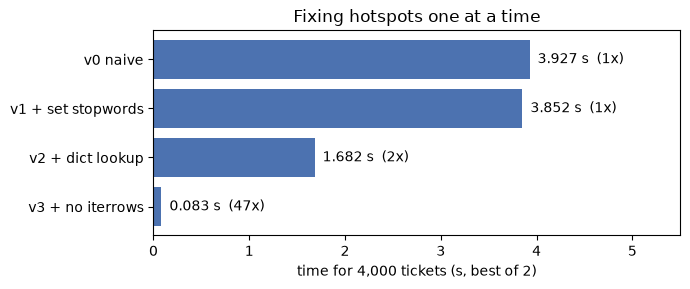

In [30]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(before_after["version"][::-1], before_after["time (s)"][::-1], color="#4C72B0")
for y, (t, s) in enumerate(zip(before_after["time (s)"][::-1], before_after["speed-up vs v0"][::-1])):
    ax.text(t, y, f"  {t:.3f} s  ({s:.0f}x)", va="center")
ax.set_xlabel("time for 4,000 tickets (s, best of 2)"); ax.set_title("Fixing hotspots one at a time")
ax.set_xlim(0, before_after["time (s)"].max() * 1.4)
plt.tight_layout(); plt.show()

**What just happened?** Each fix targeted one profiled hotspot, and the results stayed **identical** (checked with `assert_frame_equal`). Together the fixes made the pipeline **more than 10× faster** (the exact factor is in the table and depends on your machine). Two lessons:
- The biggest single step came from removing the per-row `Series` objects made by **`iterrows`**, which matches the profile, where `Series.__init__` had the largest share. The stopword **set** and the customer **dict** gave smaller gains (see the "gain of this step" column). None of these needed any clever trick.
- Profiles can mislead in the details. cProfile adds a fixed overhead to *every* call, so small, frequently called functions such as `is_stopword` (73,884 calls) look more expensive under the profiler than they really are. Always confirm a profiler's verdict with a plain timing, as this table does.

Let us profile the fast version to see what remains.

In [31]:
prof3 = cProfile.Profile()
prof3.enable(); build_features_v3(tickets, customers); prof3.disable()
s3 = io.StringIO()
pstats.Stats(prof3, stream=s3).strip_dirs().sort_stats("tottime").print_stats(5)
print(scrub(s3.getvalue()).split("Ordered by")[1])

: internal time
   List reduced from 305 to 5 due to restriction <5>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    15087    0.077    0.000    0.077    0.000 4255005557.py:5(<genexpr>)
     4000    0.031    0.000    0.214    0.000 4255005557.py:4(count_content_tokens_fast)
     4000    0.027    0.000    0.105    0.000 {built-in method builtins.sum}
     4000    0.024    0.000    0.024    0.000 {method 'lower' of 'str' objects}
        4    0.023    0.006    0.032    0.008 cast.py:123(maybe_convert_platform)





The top of the list is now the per-ticket text work inside `tokenize` and the content-token count (`re.sub`, `str.lower`, `split`, and the generator in `count_content_tokens_fast`). That is the next hotspot, and profiling always goes like this: fix the top item, re-profile, and stop when it is fast enough for the job.

**Complexity view:** v0 is $O(T \cdot (L \cdot S + C))$ for $T$ tickets with $L$ tokens each, $S$ stopwords and $C$ customers. v3 is $O(T \cdot L)$ on average.

### 7.3 Line-level and sampling profilers

`cProfile` tells you **which function**. Sometimes you need **which line**, or you need to profile a process that is already running in production.

In [32]:
try:
    import line_profiler                                    # optional: pip install line_profiler
    lp = line_profiler.LineProfiler(build_features_v0)
    lp.runcall(build_features_v0, tickets.head(500), customers)
    s = io.StringIO(); lp.print_stats(stream=s); print(scrub(s.getvalue())[:1500])
except ImportError:
    print("line_profiler is not installed (optional). Usage once installed:\n"
          "  in a notebook :  %load_ext line_profiler\n"
          "                   %lprun -f build_features_v0 build_features_v0(tickets, customers)\n"
          "  in a script   :  decorate with @profile, then run  kernprof -l -v script.py")

line_profiler is not installed (optional). Usage once installed:
  in a notebook :  %load_ext line_profiler
                   %lprun -f build_features_v0 build_features_v0(tickets, customers)
  in a script   :  decorate with @profile, then run  kernprof -l -v script.py


| Tool | Type | Overhead | Best for |
|---|---|---|---|
| `timeit`, `perf_counter` | manual timer | none | comparing two small alternatives |
| `cProfile` + `pstats` (stdlib) | deterministic, per function | medium (every call is traced) | finding the slow function; call counts |
| **line_profiler** (`kernprof`, `%lprun`) | deterministic, per line | high, but only on chosen functions | finding the slow *line* inside a function |
| **py-spy** | sampling, runs outside the process | very low | `py-spy top --pid 1234` or `py-spy record -o flame.svg --pid 1234` on a live server, with no code change |
| **Scalene** | sampling, CPU + memory (+ GPU) | low | line-level CPU *and* memory; separates time spent in Python from time spent in native code |
| **snakeviz** / flame graphs | visualiser | none | exploring `cProfile` output (`python -m cProfile -o out.prof app.py`) |

> 🎓 **Exam / interview tip:** "How would you find why an endpoint is slow in production?" → do not attach a tracing profiler to production. Use a **sampling profiler** (py-spy) or tracing spans (OpenTelemetry), find the hotspot, reproduce it locally, then use `cProfile` or line_profiler.

## 8. Memory: where did my RAM go?

*In plain English: find out which line ate the memory, and store data in compact forms.*

Out-of-memory crashes are among the most common failures in AI jobs. Examples: loading a whole data set as Python objects, caching every embedding, or keeping references to big tensors alive.

### 8.1 `tracemalloc`: snapshots and diffs
**`tracemalloc`** (standard library) records which **line** allocated each block of memory. Take a snapshot, run code, take another snapshot, and **diff** them.

In [33]:
def fmt_stat(stat):
    frame = stat.traceback[0]
    where = scrub(f"{frame.filename}:{frame.lineno}")
    return f"{where:24s} +{stat.size_diff / 1e6:6.1f} MB  (+{stat.count_diff:,} blocks)"

tracemalloc.start()
snap1 = tracemalloc.take_snapshot()

N_DOCS = 10_000
emb_rng = np.random.default_rng(3)
cache = [{"id": i, "text": f"chunk number {i} of the handbook", "embedding": emb_rng.random(64).tolist()}
         for i in range(N_DOCS)]                                   # embeddings as Python lists

snap2 = tracemalloc.take_snapshot()
diff = snap2.compare_to(snap1, "lineno")                           # sorted by size growth
noise = ("codeop.py", "<frozen", "tracemalloc.py", "IPython")      # Jupyter / tracemalloc internals
for stat in [s for s in diff if not any(n in s.traceback[0].filename for n in noise)][:2]:
    print(fmt_stat(stat))
current, peak = tracemalloc.get_traced_memory()
print(f"traced now: {current / 1e6:.1f} MB, peak: {peak / 1e6:.1f} MB")

as_array = np.array([d["embedding"] for d in cache], dtype=np.float32)   # same numbers, one block
del cache
print(f"same embeddings as a float32 array: {as_array.nbytes / 1e6:.1f} MB")
tracemalloc.stop()

<notebook-cell>:11       +  24.0 MB  (+699,566 blocks)
<notebook-cell>:10       +   0.0 MB  (+8 blocks)
traced now: 24.0 MB, peak: 24.0 MB


same embeddings as a float32 array: 2.6 MB


**What just happened?** The diff points straight at the list comprehension that built `cache`. That line added about 24 MB in roughly 700,000 blocks. Why so much? Each Python `float` is a full object (24 bytes) plus an 8-byte pointer in its list, about **32 bytes per number**. The `float32` NumPy array stores the same 640,000 numbers in **4 bytes each** (2.6 MB). Store embeddings as arrays (or in a vector database), not as lists of floats.

`tracemalloc` slows the program down while it is running, so switch it on only while investigating. For C extensions and GPUs, use **memray** or Scalene, and `torch.cuda.memory_summary()`.

### 8.2 `sys.getsizeof` lies (a little)
`sys.getsizeof(obj)` returns the size of the object **itself**, not of the objects it references. For a list, that is just the array of pointers.

In [34]:
def deep_size(obj, seen=None):
    """Approximate total memory of obj and everything it references (no double counting)."""
    seen = set() if seen is None else seen
    if id(obj) in seen:
        return 0
    seen.add(id(obj))
    size = sys.getsizeof(obj)
    if isinstance(obj, dict):
        size += sum(deep_size(k, seen) + deep_size(v, seen) for k, v in obj.items())
    elif isinstance(obj, (list, tuple, set, frozenset)):
        size += sum(deep_size(x, seen) for x in obj)
    return size

prompts = [f"user prompt number {i}: explain transformers simply" for i in range(10_000)]
emb = np.zeros((10_000, 384), dtype=np.float32)
view = emb[:100]                                         # a view: shares emb's buffer

rows = [("list of 10k strings", sys.getsizeof(prompts), deep_size(prompts)),
        ("ndarray (owns data)", sys.getsizeof(emb), emb.nbytes),
        ("ndarray view emb[:100]", sys.getsizeof(view), view.nbytes)]
pd.DataFrame(rows, columns=["object", "sys.getsizeof (bytes)", "real data (bytes)"])

,object,sys.getsizeof (bytes),real data (bytes)
0,list of 10k strings,85176,1014066
1,ndarray (owns data),15360128,15360000
2,ndarray view emb[:100],128,153600


**What just happened?** For the list, `getsizeof` counted only the pointer array (about 85 KB) and missed the 10,000 strings themselves, which add about 0.9 MB more. For an array that owns its data, `getsizeof` includes the buffer. For a **view**, it reports only the small header, because the data belongs to `emb`. Use `arr.nbytes` for NumPy arrays, `df.memory_usage(deep=True)` for pandas, and a deep walk (as above, or the `pympler` package) for nested Python objects.

### 8.3 Generators vs lists: streaming instead of loading
A **generator** produces items one at a time, on demand, so its memory use is $O(1)$ in the number of items. A list holds them all at once, $O(n)$.

In [35]:
chat_log = WORK / "chats.jsonl"
with chat_log.open("w") as f:                                   # 20k chat records, one JSON per line
    for i in range(20_000):
        f.write(json.dumps({"id": i, "tokens": (i * 37) % 900 + 20, "model": "small-llm"}) + "\n")

def mean_tokens_list(path):
    records = [json.loads(line) for line in path.open()]       # loads everything into memory
    return sum(r["tokens"] for r in records) / len(records)

def mean_tokens_stream(path):
    total = count = 0
    for line in path.open():                                   # file objects are lazy iterators
        total += json.loads(line)["tokens"]; count += 1
    return total / count

def peak_mb(fn, *args):
    tracemalloc.start(); result = fn(*args); peak = tracemalloc.get_traced_memory()[1]; tracemalloc.stop()
    return result, peak / 1e6

for fn in (mean_tokens_list, mean_tokens_stream):
    result, peak = peak_mb(fn, chat_log)
    print(f"{fn.__name__:20s} result={result:.2f}  peak memory={peak:7.2f} MB")
print("sum of squares, list vs generator peak MB:",
      round(peak_mb(lambda: sum([x * x for x in range(10**6)]))[1], 2), "vs",
      round(peak_mb(lambda: sum(x * x for x in range(10**6)))[1], 3))

mean_tokens_list     result=469.38  peak memory=   8.54 MB


mean_tokens_stream   result=469.38  peak memory=   0.03 MB


sum of squares, list vs generator peak MB: 40.45 vs 0.002


**What just happened?** Both functions give the same mean, but the list version's peak memory grows with the file size (several MB here for 20,000 lines, and gigabytes for a real data set). The streaming version stays tiny no matter how large the file is. Changing `[...]` to `(...)` inside `sum()` has the same effect. A PyTorch `IterableDataset` and the Hugging Face `datasets` streaming mode apply this same idea to training data.

### 8.4 pandas: `memory_usage(deep=True)` and dtype downcasting

In [36]:
n_rows = 200_000
g = np.random.default_rng(5)
calls = pd.DataFrame({
    "model": g.choice(["small-llm", "big-llm", "embedder", "reranker"], n_rows),   # 4 distinct strings
    "status": g.choice(["ok", "rate_limited", "error"], n_rows, p=[0.9, 0.07, 0.03]),
    "prompt_tokens": g.integers(1, 4000, n_rows),          # int64 by default
    "latency_ms": g.gamma(2.0, 150.0, n_rows),             # float64 by default
    "user_id": g.integers(0, 50_000, n_rows),
})
shallow = calls.memory_usage(deep=False).sum() / 1e6
before = calls.memory_usage(deep=True)

slim = calls.astype({"model": "category", "status": "category", "latency_ms": "float32"})
slim["prompt_tokens"] = pd.to_numeric(slim["prompt_tokens"], downcast="integer")   # -> int16
slim["user_id"] = pd.to_numeric(slim["user_id"], downcast="unsigned")              # -> uint16
after = slim.memory_usage(deep=True)

mem = pd.DataFrame({"dtype before": calls.dtypes.astype(str), "MB before": before.drop("Index") / 1e6,
                    "dtype after": slim.dtypes.astype(str), "MB after": after.drop("Index") / 1e6})
print(f"shallow estimate (deep=False): {shallow:.1f} MB  <- undercounts the string columns")
print(f"deep total: {before.sum() / 1e6:.1f} MB -> {after.sum() / 1e6:.1f} MB "
      f"({100 * (1 - after.sum() / before.sum()):.0f}% smaller)")
mem.round(2)

shallow estimate (deep=False): 8.0 MB  <- undercounts the string columns
deep total: 26.6 MB -> 2.0 MB (92% smaller)


,dtype before,MB before,dtype after,MB after
model,object,11.40,category,0.2
status,object,10.36,category,0.2
prompt_tokens,int64,1.60,int16,0.4
latency_ms,float64,1.60,float32,0.8
user_id,int64,1.60,uint16,0.4


**What just happened?** Without `deep=True`, pandas counts only the 8-byte *pointers* of the `object` (string) columns. The real cost of those two string columns is about 7 times larger (look at the "MB before" column). Converting low-cardinality strings to `category` (an integer code plus a small lookup table) and downcasting the numbers shrank the table by more than 90%.

> ⚠️ **Common mistake:** downcasting without checking the range or precision. `float32` keeps about 7 significant digits, which is fine for latency but not for money totals or IDs. `int16` overflows above 32,767. `pd.to_numeric(..., downcast=...)` picks the smallest type that holds the *current* values, so tomorrow's data may not fit. Also, `category` only helps when there are few distinct values.

### 8.5 NumPy views vs copies

A **view** is a new array object that looks at the **same memory** as the original. A **copy** has its own memory. Views are fast and free, but writing through a view changes the original, which is a classic source of "who modified my cache?" bugs.

In [37]:
embeddings = np.arange(12, dtype=np.float64).reshape(4, 3)          # pretend: 4 cached embeddings
original = embeddings.copy()

batch = embeddings[:2]                                              # slicing -> VIEW
batch /= np.linalg.norm(batch, axis=1, keepdims=True)               # in-place normalise the "batch"...
print("cache changed by normalising a slice?", not np.array_equal(embeddings, original))

a = np.arange(12).reshape(3, 4)
ops = {"a[1:]  (basic slice)": a[1:], "a[:, ::2]  (strided slice)": a[:, ::2], "a.T  (transpose)": a.T,
       "a.reshape(4, 3)": a.reshape(4, 3), "a.ravel()": a.ravel(), "a.flatten()": a.flatten(),
       "a[[0, 2]]  (fancy index)": a[[0, 2]], "a[a > 5]  (boolean mask)": a[a > 5], "a.copy()": a.copy()}
pd.DataFrame([{"operation": k, "shares memory with a?": np.shares_memory(a, v),
               "view or copy": "view" if np.shares_memory(a, v) else "copy"} for k, v in ops.items()])

cache changed by normalising a slice? True


,operation,shares memory with a?,view or copy
0,a[1:] (basic slice),True,view
1,"a[:, ::2] (strided slice)",True,view
2,a.T (transpose),True,view
3,"a.reshape(4, 3)",True,view
4,a.ravel(),True,view
5,a.flatten(),False,copy
6,"a[[0, 2]] (fancy index)",False,copy
7,a[a > 5] (boolean mask),False,copy
8,a.copy(),False,copy


**What just happened?** Normalising `batch` **in place** also changed rows 0 and 1 of the cached `embeddings`, because a basic slice is a view. **Basic slicing, transposes and (most) reshapes give views. Fancy indexing, boolean masks, `flatten()` and `copy()` give copies.** `ravel()` gives a view when it can (for contiguous arrays). If you need independence, write `batch = embeddings[:2].copy()`, or use the out-of-place `batch = batch / norms`. `np.shares_memory(a, b)` and `b.base is a` tell you which one you have.

## 9. Performance patterns

*In plain English: a handful of simple habits make Python code ten to a thousand times faster.*

### 9.1 Vectorisation: loops → NumPy
**Vectorisation** means expressing an operation on whole arrays, so the loop runs in optimised C (often with SIMD instructions and BLAS libraries) instead of the Python interpreter. The interpreter costs tens of nanoseconds of overhead per operation. C costs about one nanosecond or less.

Example: cosine similarity of one query embedding against $N$ document embeddings (the core of vector search).

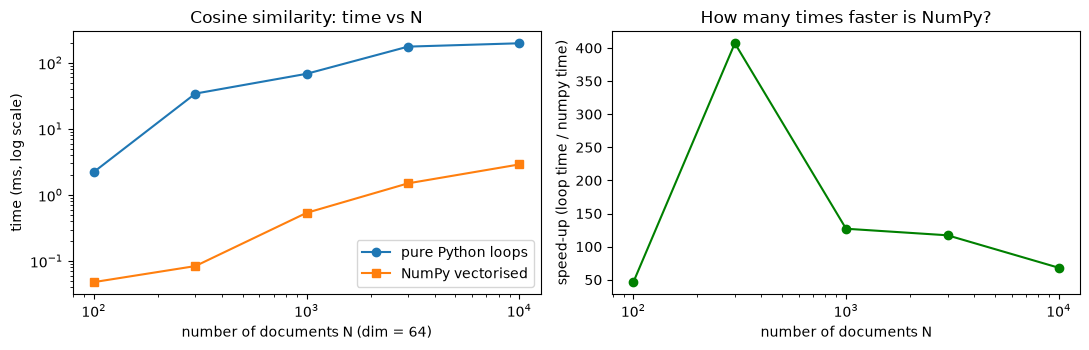

,N docs,loop (ms),numpy (ms),speed-up
0,100,2.230,0.048,46.452
1,300,34.165,0.084,407.075
2,1000,68.070,0.536,127.051
3,3000,175.523,1.498,117.139
4,10000,197.242,2.895,68.141


In [38]:
def cosine_loop(q, docs):
    q_norm = math.sqrt(sum(x * x for x in q))
    out = []
    for d in docs:                                         # Python loop over documents
        dot = sum(a * b for a, b in zip(q, d))             # ... and over dimensions
        out.append(dot / (q_norm * math.sqrt(sum(x * x for x in d))))
    return out

def cosine_numpy(q, D):
    return (D @ q) / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))   # one matrix-vector product

from contextlib import nullcontext
try:                                       # optional: pin NumPy's BLAS to 1 thread, so this is a fair
    from threadpoolctl import threadpool_limits    # single-core vs single-core comparison
    one_blas_thread = threadpool_limits(limits=1)
except ImportError:
    one_blas_thread = nullcontext()

dim = 64
vec_rows = []
with one_blas_thread:
    for n_docs in [100, 300, 1000, 3000, 10000]:
        D = rng.normal(size=(n_docs, dim)); q = rng.normal(size=dim)
        D_list, q_list = D.tolist(), q.tolist()
        t_loop = min(timeit.repeat(lambda: cosine_loop(q_list, D_list), number=1, repeat=2))
        t_np = min(timeit.repeat(lambda: cosine_numpy(q, D), number=10, repeat=3)) / 10
        assert np.allclose(cosine_loop(q_list, D_list), cosine_numpy(q, D))   # same answers
        vec_rows.append({"N docs": n_docs, "loop (ms)": t_loop * 1e3, "numpy (ms)": t_np * 1e3,
                         "speed-up": t_loop / t_np})
vec = pd.DataFrame(vec_rows)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.loglog(vec["N docs"], vec["loop (ms)"], "o-", label="pure Python loops")
ax1.loglog(vec["N docs"], vec["numpy (ms)"], "s-", label="NumPy vectorised")
ax1.set_xlabel("number of documents N (dim = 64)"); ax1.set_ylabel("time (ms, log scale)")
ax1.set_title("Cosine similarity: time vs N"); ax1.legend()
ax2.semilogx(vec["N docs"], vec["speed-up"], "o-", color="green")
ax2.set_xlabel("number of documents N"); ax2.set_ylabel("speed-up (loop time / numpy time)")
ax2.set_title("How many times faster is NumPy?")
plt.tight_layout(); plt.show()
assert vec["speed-up"].iloc[-1] > 10
vec.round(3)

**What just happened?** Both versions are $O(N \cdot d)$: for large N, both lines in the left plot rise with a slope of about 1 on the log-log axes (time grows linearly with N). NumPy's line is flatter at small N, where its fixed per-call overhead dominates. The NumPy line, though, sits far lower: the **constant factor** differs by tens to hundreds of times (see the table; the exact factor depends on your CPU and on how busy it is). We pinned NumPy's BLAS library to one thread (when `threadpoolctl` is available) so that both sides use a single core. Vectorise the inner loops that run millions of times. Do not bother for a loop of ten items.

### 9.2 Caching with `functools.lru_cache`
**Memoisation** stores the result of a pure function, keyed by its arguments, so repeated calls are free. `lru_cache(maxsize=N)` keeps the N **least-recently-used** results. Real query traffic is highly repetitive (a few popular questions dominate), so caching embeddings or retrieval results pays off.

In [39]:
def slow_embed(text: str) -> tuple:
    """Pretend embedding model call: about 1 ms of latency, deterministic output."""
    time.sleep(0.001)
    h = abs(hash(text)) % 10_000
    return tuple(round((h * k % 97) / 97, 3) for k in range(1, 5))   # immutable tuple (safe to cache)

@functools.lru_cache(maxsize=256)
def cached_embed(text: str) -> tuple:
    return slow_embed(text)

popular = [f"how do I reset my password? v{i}" for i in range(100)]
z = np.random.default_rng(11).zipf(1.6, size=600)                      # skewed popularity
queries = [popular[(k - 1) % 100] for k in z]
print("queries:", len(queries), "| distinct:", len(set(queries)))

with Timer() as t_plain:
    r1 = [slow_embed(q) for q in queries]
cached_embed.cache_clear()
with Timer() as t_cache:
    r2 = [cached_embed(q) for q in queries]
assert r1 == r2
print(f"no cache: {t_plain.seconds:.2f} s | lru_cache: {t_cache.seconds:.2f} s | {cached_embed.cache_info()}")

queries: 600 | distinct: 59


no cache: 0.70 s | lru_cache: 0.07 s | CacheInfo(hits=541, misses=59, maxsize=256, currsize=59)


**What just happened?** `cache_info()` shows that only the **distinct** queries reached the slow function (`misses`), and every repeat was a `hit`. The time dropped by about the same ratio.

> ⚠️ **Caching caveats:**
> 1. Arguments must be **hashable**, so lists and NumPy arrays cannot be keys.
> 2. Return **immutable** values. If you cache a NumPy array and a caller modifies it in place, every later caller gets the corrupted version.
> 3. `maxsize=None` (or `functools.cache`) grows **without limit**, which is effectively a memory leak.
> 4. `lru_cache` on an instance **method** keeps `self` alive. Prefer module-level functions or `cachetools`.
> 5. Only cache **pure** functions. A cached LLM call at `temperature > 0` is no longer random, and results go **stale** when the model or index changes, so put the model version in the key.

### 9.3 Choose the right data structure: list vs set membership

In [40]:
ds_rows = []
probe = [f"tok{i}" for i in range(0, 20_000, 7)]              # 2,858 lookups, some hits, some misses
for vocab_size in [10, 100, 1_000, 10_000]:
    vocab_list = [f"tok{i}" for i in range(vocab_size)]
    vocab_set = set(vocab_list)
    t_list = min(timeit.repeat(lambda: [w in vocab_list for w in probe], number=1, repeat=3))
    t_set = min(timeit.repeat(lambda: [w in vocab_set for w in probe], number=1, repeat=3))
    ds_rows.append({"vocab size": vocab_size, "list (ms)": t_list * 1e3, "set (ms)": t_set * 1e3,
                    "list / set": t_list / t_set})
pd.DataFrame(ds_rows).round(3)

,vocab size,list (ms),set (ms),list / set
0,10,1.100,0.215,5.112
1,100,22.027,0.200,110.039
2,1000,190.457,0.249,764.661
3,10000,916.152,0.365,2510.631


**What just happened?** Set lookup time stays flat as the vocabulary grows (a hash table: $O(1)$ on average), while list lookup grows linearly ($O(n)$, a scan). At 10 items the gap is only a few times. At 10,000 items the list is thousands of times slower.

| Need | Use | Why (average complexity) |
|---|---|---|
| "is x in the collection?" | `set` / `frozenset` | $O(1)$ hash lookup |
| look up by key | `dict` | $O(1)$ |
| count things | `collections.Counter` | $O(1)$ per update |
| FIFO queue (task queue, BFS) | `collections.deque` | $O(1)$ at both ends. `list.pop(0)` is $O(n)$. |
| top-k (e.g. best k retrieved chunks) | `heapq.nlargest` / a heap | $O(n \log k)$ instead of sorting $O(n \log n)$ |
| sorted data with range queries | `bisect` on a sorted list | $O(\log n)$ search |
| millions of numbers | `numpy` array | compact (4 or 8 bytes each), vectorised |

### 9.4 I/O batching
Every I/O operation has a **fixed overhead** (a system call, a disk sync, a network round trip, an HTTP request) on top of the cost per byte. Batching pays the fixed overhead once per batch instead of once per item.

In [41]:
records = [json.dumps({"request_id": i, "latency_ms": i % 300, "model": "small-llm"}) for i in range(5000)]
f_slow, f_fast = WORK / "slow.jsonl", WORK / "fast.jsonl"

with Timer() as t1:
    for r in records:
        with f_slow.open("a") as f:          # open + write + close for EVERY record
            f.write(r + "\n")
with Timer() as t2:
    with f_fast.open("w") as f:              # open once, write everything in one call
        f.write("\n".join(records) + "\n")
assert f_slow.read_text() == f_fast.read_text()

db = sqlite3.connect(WORK / "feedback.db")
db.execute("CREATE TABLE feedback (id INTEGER, rating INTEGER, comment TEXT)")
rows_db = [(i, i % 5 + 1, f"answer {i} was helpful") for i in range(100)]
with Timer() as t3:
    for row in rows_db:
        db.execute("INSERT INTO feedback VALUES (?, ?, ?)", row)
        db.commit()                          # one transaction (one disk sync) per row
db.execute("DELETE FROM feedback"); db.commit()
with Timer() as t4:
    with db:                                 # one transaction for all rows
        db.executemany("INSERT INTO feedback VALUES (?, ?, ?)", rows_db)
assert db.execute("SELECT COUNT(*) FROM feedback").fetchone()[0] == 100
db.close()

pd.DataFrame([
    {"task": "append 5,000 log lines", "one at a time (s)": t1.seconds, "batched (s)": t2.seconds},
    {"task": "insert 100 rows into SQLite", "one at a time (s)": t3.seconds, "batched (s)": t4.seconds},
]).assign(**{"speed-up": lambda d: d["one at a time (s)"] / d["batched (s)"]}).round(4)

,task,one at a time (s),batched (s),speed-up
0,"append 5,000 log lines",0.8351,0.0006,1372.9439
1,insert 100 rows into SQLite,2.2175,0.0172,128.5715


**What just happened?** Both tasks wrote exactly the same data. Batching was faster by roughly two orders of magnitude or more. The SQLite case is the most dramatic, because each `commit()` waits for the disk to confirm the write (`fsync`). The same principle applies to embedding APIs (send 100 texts per request, not 1), to database bulk loads, and to GPU inference (a batch of 32 costs far less than 32 batches of 1). The next notebook builds an async request batcher.

### 9.5 pandas anti-patterns
Task: compute the dollar cost of 20,000 LLM calls, given per-model prices for input and output tokens.

In [42]:
PRICE_IN = {"small-llm": 0.15e-6, "big-llm": 2.50e-6}      # $ per input token (made-up prices)
PRICE_OUT = {"small-llm": 0.60e-6, "big-llm": 10.0e-6}     # $ per output token
g2 = np.random.default_rng(8)
usage = pd.DataFrame({"model": g2.choice(list(PRICE_IN), 20_000),
                      "prompt_tokens": g2.integers(10, 3000, 20_000),
                      "completion_tokens": g2.integers(1, 800, 20_000)})

def cost_iterrows(df):
    out = []
    for _, r in df.iterrows():                              # builds a Series per row: very slow
        out.append(r["prompt_tokens"] * PRICE_IN[r["model"]] + r["completion_tokens"] * PRICE_OUT[r["model"]])
    return pd.Series(out, index=df.index)

def cost_apply(df):                                         # still a Python function call per row
    return df.apply(lambda r: r["prompt_tokens"] * PRICE_IN[r["model"]]
                    + r["completion_tokens"] * PRICE_OUT[r["model"]], axis=1)

def cost_itertuples(df):                                    # lighter rows (namedtuples)
    return pd.Series([r.prompt_tokens * PRICE_IN[r.model] + r.completion_tokens * PRICE_OUT[r.model]
                      for r in df.itertuples(index=False)], index=df.index)

def cost_vectorised(df):                                    # whole-column arithmetic
    return df["prompt_tokens"] * df["model"].map(PRICE_IN) + df["completion_tokens"] * df["model"].map(PRICE_OUT)

ref = cost_vectorised(usage)
pd_rows = []
for fn in (cost_iterrows, cost_apply, cost_itertuples, cost_vectorised):
    with Timer() as t:
        res = fn(usage)
    assert np.allclose(res, ref)                            # all methods agree
    pd_rows.append({"method": fn.__name__, "time (s)": t.seconds})
pdt = pd.DataFrame(pd_rows)
pdt["slower than vectorised"] = pdt["time (s)"] / pdt["time (s)"].iloc[-1]
print(f"total cost of 20,000 calls: ${ref.sum():,.2f}")
pdt.round(4)

total cost of 20,000 calls: $82.96


,method,time (s),slower than vectorised
0,cost_iterrows,6.3949,203.4039
1,cost_apply,1.4614,46.4830
2,cost_itertuples,0.1249,3.9733
3,cost_vectorised,0.0314,1.0000


**What just happened?** All four methods give the same total. `iterrows` creates a whole pandas `Series` for every row, so it is the slowest. `apply(axis=1)` is *not* vectorised: it is still a Python call per row. `itertuples` is a lot faster, but still a Python loop. The vectorised version does whole-column arithmetic in C and wins by two to three orders of magnitude.

**Chained assignment** is the other classic pandas trap: `df[mask]["col"] = value` first creates a *temporary* filtered DataFrame (`df[mask]`), then sets a column on that temporary, and `df` is left unchanged.

In [43]:
answers = pd.DataFrame({"confidence": [0.92, 0.41, 0.77, 0.30], "action": ["send"] * 4})

with warnings.catch_warnings(record=True) as caught:        # capture instead of spamming the output
    warnings.simplefilter("always")
    answers[answers["confidence"] < 0.5]["action"] = "human_review"   # chained assignment
print("warnings raised :", [w.category.__name__ for w in caught])
print("after chained   :", answers["action"].tolist(), "<- unchanged!")

answers.loc[answers["confidence"] < 0.5, "action"] = "human_review"  # one .loc call: row mask + column
print("after .loc      :", answers["action"].tolist())

warnings raised : ['SettingWithCopyWarning']
after chained   : ['send', 'send', 'send', 'send'] <- unchanged!
after .loc      : ['send', 'human_review', 'send', 'human_review']


**What just happened?** The chained version raised a `SettingWithCopyWarning` and did **not** route the low-confidence answers to human review. That is a silent safety bug in an LLM application. A single `.loc[row_mask, column]` assignment works. In **pandas 3.0 and later**, *Copy-on-Write* is the default: chained assignment *never* modifies the original and emits a `ChainedAssignmentError` warning instead. The fix is the same `.loc` call.

| Anti-pattern | Better |
|---|---|
| `for _, r in df.iterrows()` | column arithmetic, `.map`, `np.where`, `np.select` |
| `df.apply(f, axis=1)` with simple arithmetic | vectorised column expressions |
| `df = pd.concat([df, row])` inside a loop ($O(n^2)$ copying) | collect rows in a list, build one DataFrame at the end |
| `df[mask]["col"] = v` | `df.loc[mask, "col"] = v` |
| string columns with few values | `category` dtype |
| reading a huge CSV in one go | `usecols=`, `dtype=`, `chunksize=`, or Parquet / Polars / DuckDB |

## 10. The PyTorch profiler (optional, briefly)

*In plain English: the same "measure first" idea, applied to the layers of a neural network.*

`cProfile` sees Python functions, but a neural network spends its time in **C++/CUDA operators** (`aten::addmm` is a matrix multiply plus a bias add, `aten::softmax`, and so on). `torch.profiler` records those operators, together with labels you add with `record_function`.

We run the example in a **subprocess**. This keeps PyTorch's start-up cost and its native log lines out of the notebook, and the cell simply prints a message if PyTorch is not installed. We use one CPU thread so the numbers are stable.

In [44]:
TORCH_PROF = """
import warnings
warnings.filterwarnings("ignore")
import torch
from torch.profiler import profile, ProfilerActivity, record_function
torch.manual_seed(0); torch.set_num_threads(1)
model = torch.nn.Sequential(torch.nn.Linear(256, 1024), torch.nn.ReLU(), torch.nn.Linear(1024, 10))
x = torch.randn(64, 256)
for _ in range(3):                          # warm-up: the first calls are slower
    model(x)
with profile(activities=[ProfilerActivity.CPU], record_shapes=True) as prof:
    for _ in range(5):
        with record_function("model_forward"):
            logits = model(x)
        with record_function("softmax_head"):
            probs = logits.softmax(dim=-1)
print(prof.key_averages().table(sort_by="cpu_time_total", row_limit=7))
"""
(WORK / "torch_prof.py").write_text(TORCH_PROF)
r = subprocess.run([sys.executable, str(WORK / "torch_prof.py")], capture_output=True, text=True,
                   env={**os.environ, "KINETO_LOG_LEVEL": "5"})
if r.returncode == 0:
    print(scrub(r.stdout))
elif "No module named 'torch'" in r.stderr:
    print("PyTorch is not installed. This section is optional; skip it.")
else:
    print("torch profiler failed:", scrub(r.stderr.strip().splitlines()[-1]))

----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                  Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
         model_forward        37.14%      10.331ms        97.35%      27.078ms       5.416ms             5  
          aten::linear         0.37%     102.463us        32.77%       9.115ms     911.537us            10  
           aten::addmm        30.36%       8.446ms        31.45%       8.749ms     874.894us            10  
            aten::relu         0.43%     119.763us        27.43%       7.631ms       1.526ms             5  
       aten::clamp_min        27.00%       7.511ms        27.00%       7.511ms       1.502ms             5  
          softmax_head         1.72%     477.594us         2.65%     736.800us     147.360us             5  
               aten

**What just happened?** The table lists operators by **total CPU time**. Our label `model_forward` contains the two `aten::linear` → `aten::addmm` calls (10 = 2 layers × 5 iterations), and they dominate. The `softmax_head` label takes a smaller share. **Self CPU** is time inside that operator only, and **CPU total** includes its children, the same distinction as `tottime` and `cumtime` in `pstats`.

For real training runs, use `schedule=torch.profiler.schedule(wait=1, warmup=1, active=3)` to skip the start-up steps, and `on_trace_ready=torch.profiler.tensorboard_trace_handler(dir)` (or `prof.export_chrome_trace(...)`) to get a timeline. On a GPU, add `ProfilerActivity.CUDA`. When timing by hand on a GPU, call `torch.cuda.synchronize()` first, because CUDA kernels run **asynchronously** and a plain timer would only measure the kernel launch. See [Inference optimisation](../08_LLM/13_inference_optimization.ipynb) for what to do with the results.

## 11. Big-O meets the real world: constant factors

*In plain English: the "better" algorithm on paper is not always faster on small, real inputs.*

Big-O describes how cost **grows** with input size $n$. It deliberately ignores constant factors and lower-order terms: $T(n) = c_1 n^2$ versus $T(n) = c_2 n \log n$. For small $n$, or when $c_1 \ll c_2$, the "worse" algorithm wins. Real libraries exploit this. CPython's `sorted` (Timsort, and since Python 3.11 its Powersort merge policy) uses **insertion sort** on short runs, and many quicksort implementations switch to insertion sort below about 16 to 32 elements.

Experiment: pure-Python insertion sort, $O(n^2)$, against pure-Python merge sort, $O(n \log n)$, and the built-in `sorted`, $O(n \log n)$ in C.

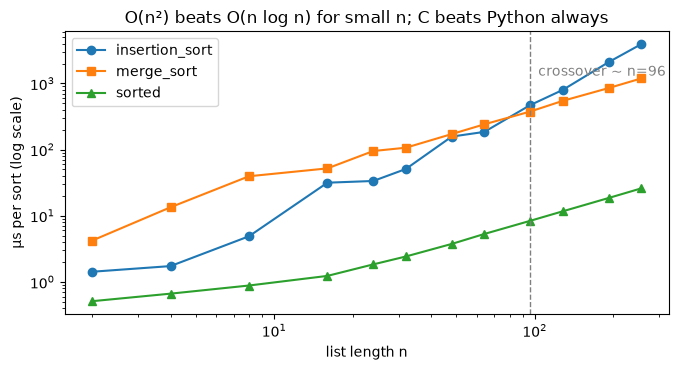

insertion sort is faster than merge sort for n < 96
built-in sorted vs pure-Python merge sort at n=256: 46x faster


In [45]:
def insertion_sort(a):
    a = list(a)
    for i in range(1, len(a)):
        key, j = a[i], i - 1
        while j >= 0 and a[j] > key:         # shift larger elements one place right
            a[j + 1] = a[j]; j -= 1
        a[j + 1] = key
    return a

def merge_sort(a):
    if len(a) <= 1:
        return list(a)
    mid = len(a) // 2
    left, right = merge_sort(a[:mid]), merge_sort(a[mid:])
    out, i, j = [], 0, 0
    while i < len(left) and j < len(right):  # merge two sorted halves
        if left[i] <= right[j]: out.append(left[i]); i += 1
        else: out.append(right[j]); j += 1
    return out + left[i:] + right[j:]

sizes = [2, 4, 8, 16, 24, 32, 48, 64, 96, 128, 192, 256]
srng = random.Random(0)
bo_rows = []
for n_ in sizes:
    data = [srng.random() for _ in range(n_)]
    assert insertion_sort(data) == merge_sort(data) == sorted(data)
    reps = max(20, 4000 // n_)
    row = {"n": n_}
    for fn in (insertion_sort, merge_sort, sorted):
        row[fn.__name__] = min(timeit.repeat(lambda: fn(data), number=reps, repeat=3)) / reps * 1e6
    bo_rows.append(row)
bo = pd.DataFrame(bo_rows)
crossover = bo.loc[bo["insertion_sort"] > bo["merge_sort"], "n"].min()

fig, ax = plt.subplots(figsize=(7, 3.8))
for col, style in [("insertion_sort", "o-"), ("merge_sort", "s-"), ("sorted", "^-")]:
    ax.loglog(bo["n"], bo[col], style, label=col)
ax.axvline(crossover, color="grey", ls="--", lw=1)
ax.text(crossover, bo["insertion_sort"].max() / 3, f"  crossover ~ n={crossover}", color="grey")
ax.set_xlabel("list length n"); ax.set_ylabel("µs per sort (log scale)")
ax.set_title("O(n²) beats O(n log n) for small n; C beats Python always"); ax.legend()
plt.tight_layout(); plt.show()
print("insertion sort is faster than merge sort for n <", crossover)
print(f"built-in sorted vs pure-Python merge sort at n=256: {bo['merge_sort'].iloc[-1] / bo['sorted'].iloc[-1]:.0f}x faster")

**What just happened?** For short lists the $O(n^2)$ insertion sort beats our $O(n \log n)$ merge sort, because it has no recursion, no slicing and no new lists. Beyond the crossover (printed above; with these pure-Python versions it usually falls somewhere between about 20 and about 130 elements, and it moves around with machine load), the asymptotics take over. The built-in `sorted` is the same complexity class as merge sort, yet it is many times faster at every size, because it is written in C. Constant factors matter.

Other places where constants beat asymptotics:
- **Memory locality:** NumPy arrays are contiguous, so the CPU cache and SIMD units work well. A Python list of objects scatters its data around memory.
- **Small $n$:** a linear scan of 5 items can beat a hash lookup, because there is no hashing.
- **Hardware:** on a GPU, an "inefficient" dense $O(n^2)$ attention can beat a clever sparse method for moderate $n$. This is why FlashAttention optimised *memory traffic* rather than changing the complexity.

> 🎓 **Exam / interview tip:** when asked "which is faster?", answer in two parts: asymptotically (Big-O), and in practice (constants, memory, $n$ in the real workload). Then say "I would measure it".

## 🔗 How this connects to modern AI

| Technique here | Where it shows up in AI engineering |
|---|---|
| Debugging loop + regression tests | every fixed bug in a data pipeline or prompt template becomes a test case in CI ([Testing in ML](../15_MLOps/07_testing_in_ml/01_testing_ml.ipynb)) |
| Structured JSON logs + request IDs | LLM observability: traces of each request with model, tokens, latency and cost ([Agent observability](../10_Agents/06_agent_observability.ipynb), [Monitoring](../15_MLOps/06_monitoring/01_monitoring.ipynb)) |
| Redaction filters | stopping API keys and personal data from leaking into logs ([LLM security](../08_LLM/16_llm_security.ipynb)) |
| NaN / shape / broadcasting checks | training stability, mixed precision (`float16` overflows at 65,504), attention masks |
| Leakage checks | honest evaluation, benchmark contamination checks for LLMs |
| Profilers | finding the data-loader bottleneck that keeps a GPU idle; [inference optimisation](../08_LLM/13_inference_optimization.ipynb) |
| Memory tools, dtype downcasting | quantisation (fp32 → int8 / int4 is the same idea as `float64` → `float32` here), fitting models into GPU memory |
| Vectorisation, batching, caching | vector search, batched inference, prompt / KV caching in LLM servers |

## Recap
- Debug with a loop: **reproduce → isolate → hypothesise → test → fix → regression test**, and make the test fail on the buggy code first.
- Read tracebacks **from the bottom**. `raise New(...) from err` sets `__cause__` (deliberate translation). Errors inside `except` set `__context__`.
- Use **logging**, not `print`: levels, handlers, formatters and filters. Libraries never configure logging. Prefer JSON logs with request IDs, and redact secrets.
- `breakpoint()` + pdb (`n s c p pp w u d b ll`), post-mortem with `python -m pdb -c continue`, `%debug`, or `pdb.post_mortem`.
- `assert` checks invariants (and is removed by `-O`). `raise ValueError` validates input.
- The five ML bugs: NaN/inf (stable softmax, `errstate`), shape bugs (test with distinct sizes), silent broadcasting (assert shapes), leakage (pipelines inside CV, random-label check), label misalignment (align by index).
- **Measure, don't guess:** `perf_counter`/`timeit` (take the minimum), `cProfile` + `pstats` (`tottime` finds hotspots), then line_profiler / py-spy / Scalene.
- Memory: `tracemalloc` diffs, deep sizes rather than `getsizeof`, generators, `memory_usage(deep=True)`, `category`/downcasting, views vs copies.
- Performance: vectorise, cache pure functions, pick the right data structure, batch I/O, avoid `iterrows`/`apply`/chained assignment. Big-O tells you the trend; constants decide small cases.

## Practice problems

**1. (Easy, conceptual)** What is printed between the two tracebacks in each case, and which attribute links them? (a) An exception is raised inside an `except` block by accident. (b) `raise ConfigError(...) from err`.

<details><summary>Show solution</summary>

(a) *"During handling of the above exception, another exception occurred:"*. The new exception's `__context__` points to the original.
(b) *"The above exception was the direct cause of the following exception:"*. `__cause__` points to `err` (and `__context__` is set too, but `__suppress_context__` is `True`, so only the cause is displayed).
</details>

**2. (Easy, coding)** Write a `logging.Filter` that replaces e-mail addresses in log messages with `<email>`.

<details><summary>Show solution</summary>

```python
import logging, re

class RedactEmails(logging.Filter):
    PATTERN = re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")
    def filter(self, record):
        record.msg = self.PATTERN.sub("<email>", record.getMessage())
        record.args = None
        return True

# test
rec = logging.LogRecord("x", logging.INFO, "app.py", 1, "user %s asked about refunds", ("jane.doe@example.com",), None)
RedactEmails().filter(rec)
assert rec.getMessage() == "user <email> asked about refunds"
```
</details>

**3. (Medium, coding)** This regression metric is wrong. Find and fix the bug, and add a check that would have caught it.
```python
def mae(y_true, y_pred):            # y_true shape (n,), y_pred from model.predict(X).reshape(-1, 1)
    return np.mean(np.abs(y_true - y_pred))
```

<details><summary>Show solution</summary>

`y_true - y_pred` broadcasts `(n,)` against `(n, 1)` into `(n, n)`. Fix: flatten and check the shapes.
```python
def mae(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    if y_true.shape != y_pred.shape:
        raise ValueError(f"shape mismatch {y_true.shape} vs {y_pred.shape}")
    return float(np.mean(np.abs(y_true - y_pred)))

assert mae(np.array([1.0, 2.0, 3.0]), np.array([[1.5], [2.0], [2.0]])) == 0.5
```
</details>

**4. (Medium, conceptual)** A teammate reports 97% accuracy on a churn model. Their notebook does `StandardScaler().fit_transform(X)`, then `SelectKBest(k=50).fit_transform(X, y)`, then `cross_val_score(model, X, y)`. What is wrong, and how do you prove it?

<details><summary>Show solution</summary>

Both the scaler and, much more seriously, the feature selector were fitted on **all** rows, including the rows that later serve as test folds. The label information leaked into feature selection. To prove it, rerun the same notebook with **shuffled labels**: if the accuracy stays well above the majority-class rate, there is leakage. To fix it, put the scaler, selector and model in one `Pipeline` and cross-validate the pipeline. Also check for target-leaking columns and for time ordering (use `TimeSeriesSplit` if churn depends on time).
</details>

**5. (Medium, coding)** Speed this up and say what the complexity becomes:
```python
def docs_containing(queries, docs):          # docs: list of token lists
    return {q: sum(1 for d in docs if q in d) for q in queries}
```

<details><summary>Show solution</summary>

Each `q in d` scans a list, so the total is $O(Q \cdot D \cdot L)$. Build an index once: a `Counter` of the distinct tokens per document (document frequency). That costs $O(D \cdot L)$, and then each query is an $O(1)$ lookup, for $O(D \cdot L + Q)$ in total.
```python
from collections import Counter

def docs_containing_fast(queries, docs):
    df = Counter(tok for d in docs for tok in set(d))
    return {q: df[q] for q in queries}

docs_ = [["gpu", "slow"], ["gpu", "gpu", "crash"], ["login"]]
assert docs_containing_fast(["gpu", "login", "x"], docs_) == {"gpu": 2, "login": 1, "x": 0}
```
</details>

**6. (Medium, conceptual)** For `a = np.arange(10)`, which of these are views: `a[::2]`, `a[[0, 2]]`, `a[a > 3]`, `a.reshape(2, 5)`, `a[None, :]`, `a.astype(float)`?

<details><summary>Show solution</summary>

Views: `a[::2]` (basic strided slice), `a.reshape(2, 5)` (contiguous reshape), `a[None, :]` (adds an axis). Copies: `a[[0, 2]]` (fancy indexing), `a[a > 3]` (boolean mask), `a.astype(float)` (new dtype means new memory). Check with `np.shares_memory(a, x)`.
</details>

**7. (Hard, coding)** Write a decorator `@timed(logger)` that logs a function's duration (measured with `perf_counter`) at DEBUG level, and a context manager `peak_memory()` that reports the peak traced memory in MB.

<details><summary>Show solution</summary>

```python
import functools, logging, time, tracemalloc
from contextlib import contextmanager

def timed(logger):
    def deco(fn):
        @functools.wraps(fn)                         # keep name/docstring
        def wrapper(*args, **kwargs):
            t0 = time.perf_counter()
            try:
                return fn(*args, **kwargs)
            finally:                                 # log even if fn raises
                logger.debug("%s took %.2f ms", fn.__name__, (time.perf_counter() - t0) * 1e3)
        return wrapper
    return deco

@contextmanager
def peak_memory():
    result = {}
    tracemalloc.start()
    try:
        yield result
    finally:
        result["peak_mb"] = tracemalloc.get_traced_memory()[1] / 1e6
        tracemalloc.stop()

# test
records = []
class ListHandler(logging.Handler):
    def emit(self, record): records.append(record.getMessage())
lg = logging.getLogger("timed-test"); lg.setLevel(logging.DEBUG); lg.addHandler(ListHandler())

@timed(lg)
def build(n): return [0] * n

with peak_memory() as m:
    build(1_000_000)
assert records and records[0].startswith("build took")
assert m["peak_mb"] > 7          # 1M pointers = 8 MB
```
</details>

## Further reading
- Andreas Zeller, *Why Programs Fail: A Guide to Systematic Debugging* (2nd ed.), chapters 1–6 (the scientific method of debugging), and the free online *The Debugging Book* (debuggingbook.org).
- Micha Gorelick and Ian Ozsvald, *High Performance Python* (2nd ed.), chapters 2 (profiling), 4 (dictionaries and sets), 6 (matrix and vector computation, NumPy and pandas).
- Brett Slatkin, *Effective Python* (3rd ed.), the items on profiling (`cProfile`), `tracemalloc`, `deque`, `bisect` and `heapq`.
- Python docs: the *Logging HOWTO* and *Logging Cookbook*, `pdb`, *The Python Profilers*, and `tracemalloc` (docs.python.org).
- Cormen et al., *Introduction to Algorithms* (CLRS), chapter 2 (insertion sort and merge sort, analysed), and chapter 3 (asymptotic notation and its limits).

## Clean up

In [46]:
logging.getLogger("rag").handlers.clear()                 # detach our handlers
shutil.rmtree(WORK, ignore_errors=True)                   # delete every file this notebook created
print("temporary folder removed:", not WORK.exists())

temporary folder removed: True


## Next notebook
➡️ [Concurrency and async](05_concurrency_and_async.ipynb): threads, processes, the GIL and free-threaded Python, `asyncio`, and how to make 100 LLM calls at once with retries and rate limits.

⬅️ Previous: [Testing AI code](03_testing_ai_code.ipynb)